In [ ]:
%pip install imbalanced-learn

##Caricamento dati e raggruppamento target

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.ensemble import RandomForestClassifier
import imblearn
from imblearn.over_sampling import SMOTE

In [ ]:
# CARICAMENTO DATI
df = pd.read_csv('Mace.csv', sep=';', encoding='latin1')
if 'Informazioni cronologiche' in df.columns:
    df = df.drop('Informazioni cronologiche', axis=1)

for col in df.columns:
    if df[col].dtype == 'object':
        df[col] = df[col].fillna('Sconosciuto')
    else:
        df[col] = df[col].fillna(df[col].median())


In [ ]:
# RAGGRUPPAMENTO TARGET (4 GRUPPI)
target_col = 'Quale artista speri di vedere stasera?'
artist_counts = df[target_col].value_counts()

clusters = {
    'Trap_NuovaScena': ['Izi', 'Kid Yugi', 'Tony Boy', 'Astro', 'Geolier', 'Samurai Jay', 'Ketama126', 'Ele A'],
    'Rap_Storico': ['Gemitaiz', 'Salmo', 'Fabri Fibra', 'Noyz Narcos', 'Gué', 'Jake la Furia'],
    'Indie_Pop': ['Frah Quintale', 'Marco Mengoni', 'Centomilacarie', 'Franco126', 'Marco Castello', 'Chiello', 'Madame', 'Blanco', 'Psicologi', 'Rkomi', 'Fulminacci', 'Rosa Chemical', 'Colapesce'],
    'Alternative_Elettronica': ['Venerus', 'Cosmo', 'Joan Thiele', 'Altea']
}

cluster_mapping = {}
for cluster_name, artists in clusters.items():
    valid_artists = [a for a in artists if a in artist_counts.index]
    if valid_artists:
        counts = artist_counts[valid_artists]
        capogruppo = counts.idxmax()
        for artist in valid_artists:
          cluster_mapping[artist] = capogruppo
df[target_col] = df[target_col].map(cluster_mapping)

##Exploratory Data Analysis

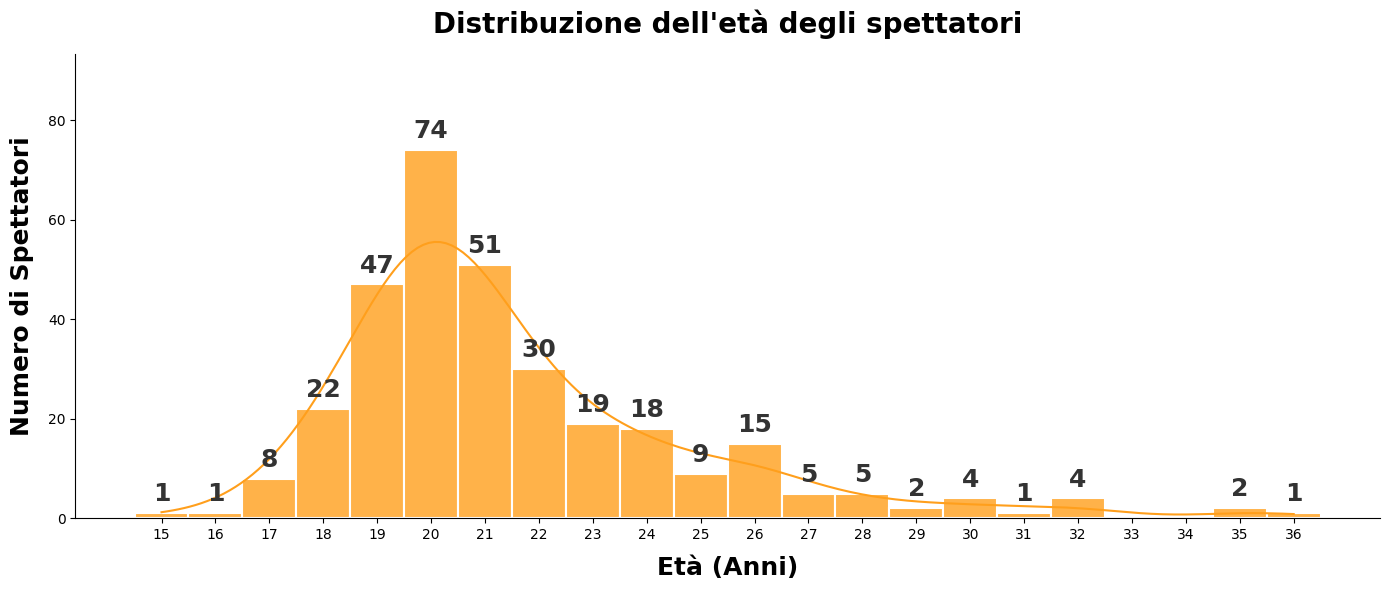

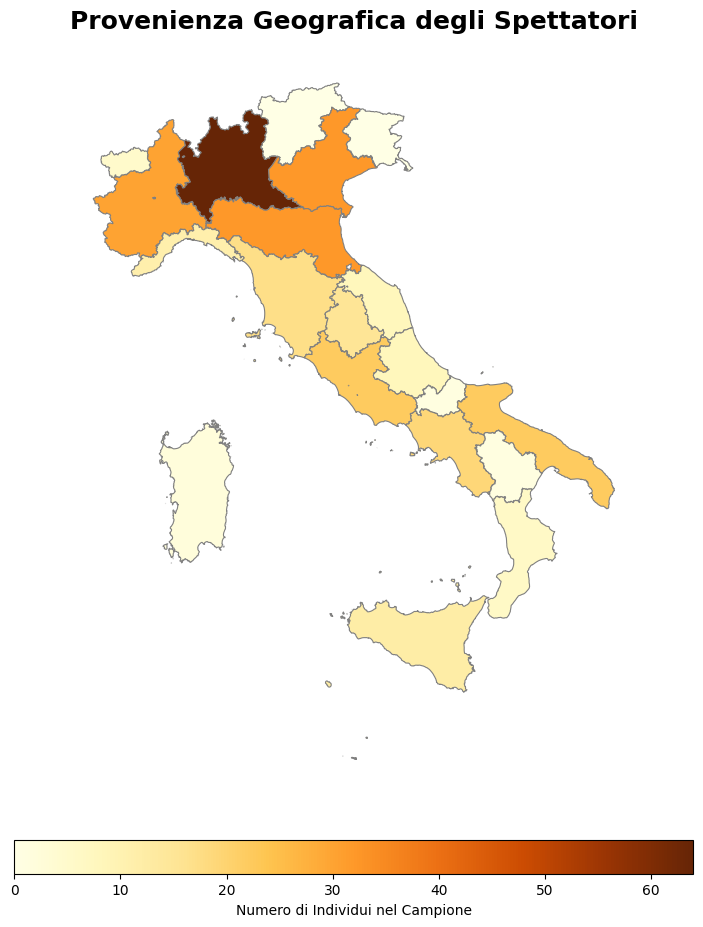

In [ ]:
# GRAFICO DISTRIBUZIONE ETA'

import geopandas as gpd

df_raw = pd.read_csv('Mace.csv', sep=';', encoding='latin1') # DATASET GREZZO
df_raw['Quanti anni hai?'] = pd.to_numeric(df_raw['Quanti anni hai?'], errors='coerce') # Pulizia della colonna forzandola a numero
df_eta_originale = df_raw.dropna(subset=['Quanti anni hai?']) # Rimuoviamo i valori nulli

plt.figure(figsize=(14, 6))

# istogramma con una barra per ogni singolo anno di età
ax = sns.histplot(
    data=df_eta_originale,
    x='Quanti anni hai?',
    discrete=True,
    kde=True,
    color='#FF9F1C',
    edgecolor='white',
    linewidth=1.5,
    alpha=0.8
)

plt.title("Distribuzione dell'età degli spettatori", fontsize=20, fontweight='bold', pad=15)
plt.xlabel("Età (Anni)", fontsize=18, fontweight='bold', labelpad=10)
plt.ylabel("Numero di Spettatori", fontsize=18, fontweight='bold', labelpad=10)

# Aggiungiamo i numeri esatti sopra ogni singola barra
for p in ax.patches:
    altezza = p.get_height()
    if altezza > 0: # Mostra il numero solo se c'è almeno 1 persona di quell'età
        ax.annotate(f"{int(altezza)}",
                    (p.get_x() + p.get_width() / 2., altezza),
                    ha='center', va='bottom',
                    fontsize=18, fontweight='bold', color='#333333',
                    xytext=(0, 5), textcoords='offset points')

eta_min = int(df_eta_originale['Quanti anni hai?'].min())
eta_max = int(df_eta_originale['Quanti anni hai?'].max())
plt.xticks(range(eta_min, eta_max + 1))
plt.ylim(0, ax.get_ylim()[1] * 1.20)

sns.despine()
plt.tight_layout()
plt.show()

# Grafico provenienza
df_mappa = pd.read_csv('Mace.csv', sep=';', encoding='latin1')
conteggio_regioni = df_mappa['Da quale regione provieni?'].value_counts().reset_index()
conteggio_regioni.columns = ['Regione', 'Numero Spettatori']

# Rimuoviamo eventuali valori nulli o non validi
conteggio_regioni = conteggio_regioni[conteggio_regioni['Regione'] != 'Sconosciuto']

url_geojson = 'https://raw.githubusercontent.com/openpolis/geojson-italy/master/geojson/limits_IT_regions.geojson'
italy = gpd.read_file(url_geojson)
mappa_nomi = {
    "Valle d'Aosta/Vallée d'Aoste": "Valle d'Aosta",
    "Trentino-Alto Adige/Südtirol": "Trentino Alto Adige",
    "Friuli-Venezia Giulia": "Friuli Venezia Giulia",
    "Emilia-Romagna": "Emilia Romagna",
    "Sicilia": "Sicilia", "Sardegna": "Sardegna", "Calabria": "Calabria",
    "Basilicata": "Basilicata", "Puglia": "Puglia", "Campania": "Campania",
    "Molise": "Molise", "Abruzzo": "Abruzzo", "Lazio": "Lazio",
    "Umbria": "Umbria", "Marche": "Marche", "Toscana": "Toscana",
    "Liguria": "Liguria", "Piemonte": "Piemonte", "Lombardia": "Lombardia",
    "Veneto": "Veneto"
}
italy['reg_name_clean'] = italy['reg_name'].map(lambda x: mappa_nomi.get(x, x))

mappa_completa = italy.merge(conteggio_regioni, left_on='reg_name_clean', right_on='Regione', how='left')

# Le regioni senza intervistati le mettiamo a 0
mappa_completa['Numero Spettatori'] = mappa_completa['Numero Spettatori'].fillna(0)

fig, ax = plt.subplots(1, 1, figsize=(10, 10))
mappa_completa.plot(
    column='Numero Spettatori',
    ax=ax,
    cmap='YlOrBr',
    linewidth=0.8,
    edgecolor='0.5',
    legend=True,
    legend_kwds={
        'label': "Numero di Individui nel Campione",
        'orientation': "horizontal",
        'shrink': 0.7,
        'pad': 0.05
    }
)

ax.set_axis_off()
plt.title('Provenienza Geografica degli Spettatori', fontsize=18, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

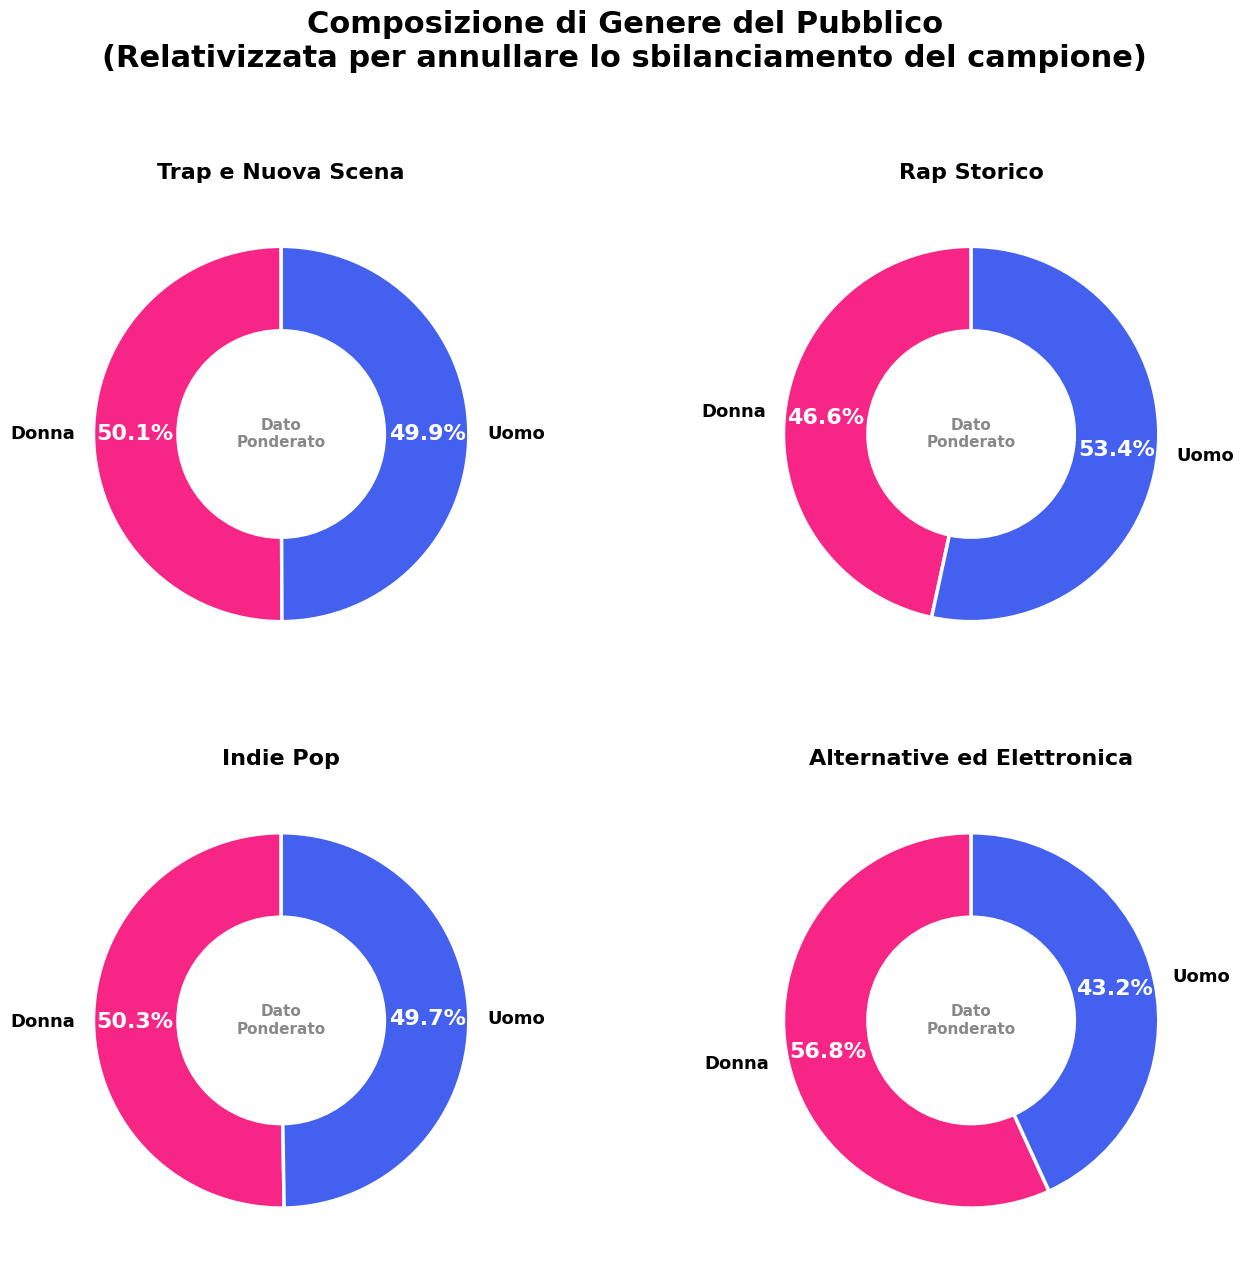

In [ ]:
# GRAFICI PREFERENZE MUSICALI PER GENERE

#mappatura dei cluster
cluster_mapping = {}
for cluster_name, artists in clusters.items():
    for artist in artists:
        cluster_mapping[artist] = cluster_name

df_gender = pd.read_csv('Mace.csv', sep=';', encoding='latin1')
target_col = 'Quale artista speri di vedere stasera?'
colonna_genere = 'Qual è il tuo genere?'

# Mappiamo i target musicali
df_gender['Cluster'] = df_gender[target_col].map(cluster_mapping).fillna('Altro')
df_gender = df_gender[~df_gender['Cluster'].isin(['Altro', 'Sconosciuto'])]
df_gender = df_gender[df_gender[colonna_genere].notna()]

# ---> RIMOZIONE DELLA CATEGORIA 'Altro' DAL GENERE <---
df_gender = df_gender[df_gender[colonna_genere] != 'Altro']

totali_per_sesso = df_gender[colonna_genere].value_counts()

gender_colors = {
    'Uomo': '#4361EE',
    'Donna': '#F72585',
    'Non binario': '#4CC9F0',
    'Preferisco non specificare': '#808080'
}

# DISEGNO DEI 4 DONUT CHARTS (Griglia 2x2)

configurazione_plot = [
    ('Trap_NuovaScena', 'Trap e Nuova Scena'),
    ('Rap_Storico', 'Rap Storico'),
    ('Indie_Pop', 'Indie Pop'),
    ('Alternative_Elettronica', 'Alternative ed Elettronica')
]

fig, axs = plt.subplots(2, 2, figsize=(14, 12))
axs = axs.flatten()

for idx, (cluster_col, titolo_bello) in enumerate(configurazione_plot):
    ax = axs[idx]

    # Isoliamo chi ascolta questo cluster
    pubblico_genere = df_gender[df_gender['Cluster'] == cluster_col]

    if len(pubblico_genere) > 0:
        # Conteggio GREZZO all'interno del cluster
        conteggi_raw = pubblico_genere[colonna_genere].value_counts()

        # PONDERAZIONE (Neutralizzazione dello sbilanciamento)
        pesi_relativi = {}
        for sesso, voti in conteggi_raw.items():
            pesi_relativi[sesso] = voti / totali_per_sesso[sesso]

        serie_pesi = pd.Series(pesi_relativi)
        dati_torta = (serie_pesi / serie_pesi.sum()) * 100

        colori_fette = [gender_colors.get(genere, '#333333') for genere in dati_torta.index]

        wedges, texts, autotexts = ax.pie(
            dati_torta,
            labels=dati_torta.index,
            autopct='%1.1f%%',
            startangle=90,
            colors=colori_fette,
            pctdistance=0.78,
            wedgeprops=dict(width=0.45, edgecolor='white', linewidth=2.5)
        )

        plt.setp(autotexts, size=16, weight="bold", color="white")
        plt.setp(texts, size=13, weight="bold")
        for autotext, colore in zip(autotexts, colori_fette):
            if colore in ['#4CC9F0', '#FFD166', '#808080']:
                autotext.set_color('black')

        ax.set_title(titolo_bello, fontsize=16, fontweight='bold', pad=15)
        ax.text(0, 0, "Dato\nPonderato", ha='center', va='center', fontsize=11, fontweight='bold', color='#888888')
    else:
        ax.text(0.5, 0.5, "Nessun dato disponibile", ha='center', va='center')
        ax.set_axis_off()

plt.suptitle("Composizione di Genere del Pubblico\n(Relativizzata per annullare lo sbilanciamento del campione)", fontsize=22, fontweight='bold', y=1.05)
plt.tight_layout()
plt.subplots_adjust(hspace=0.25)
plt.show()

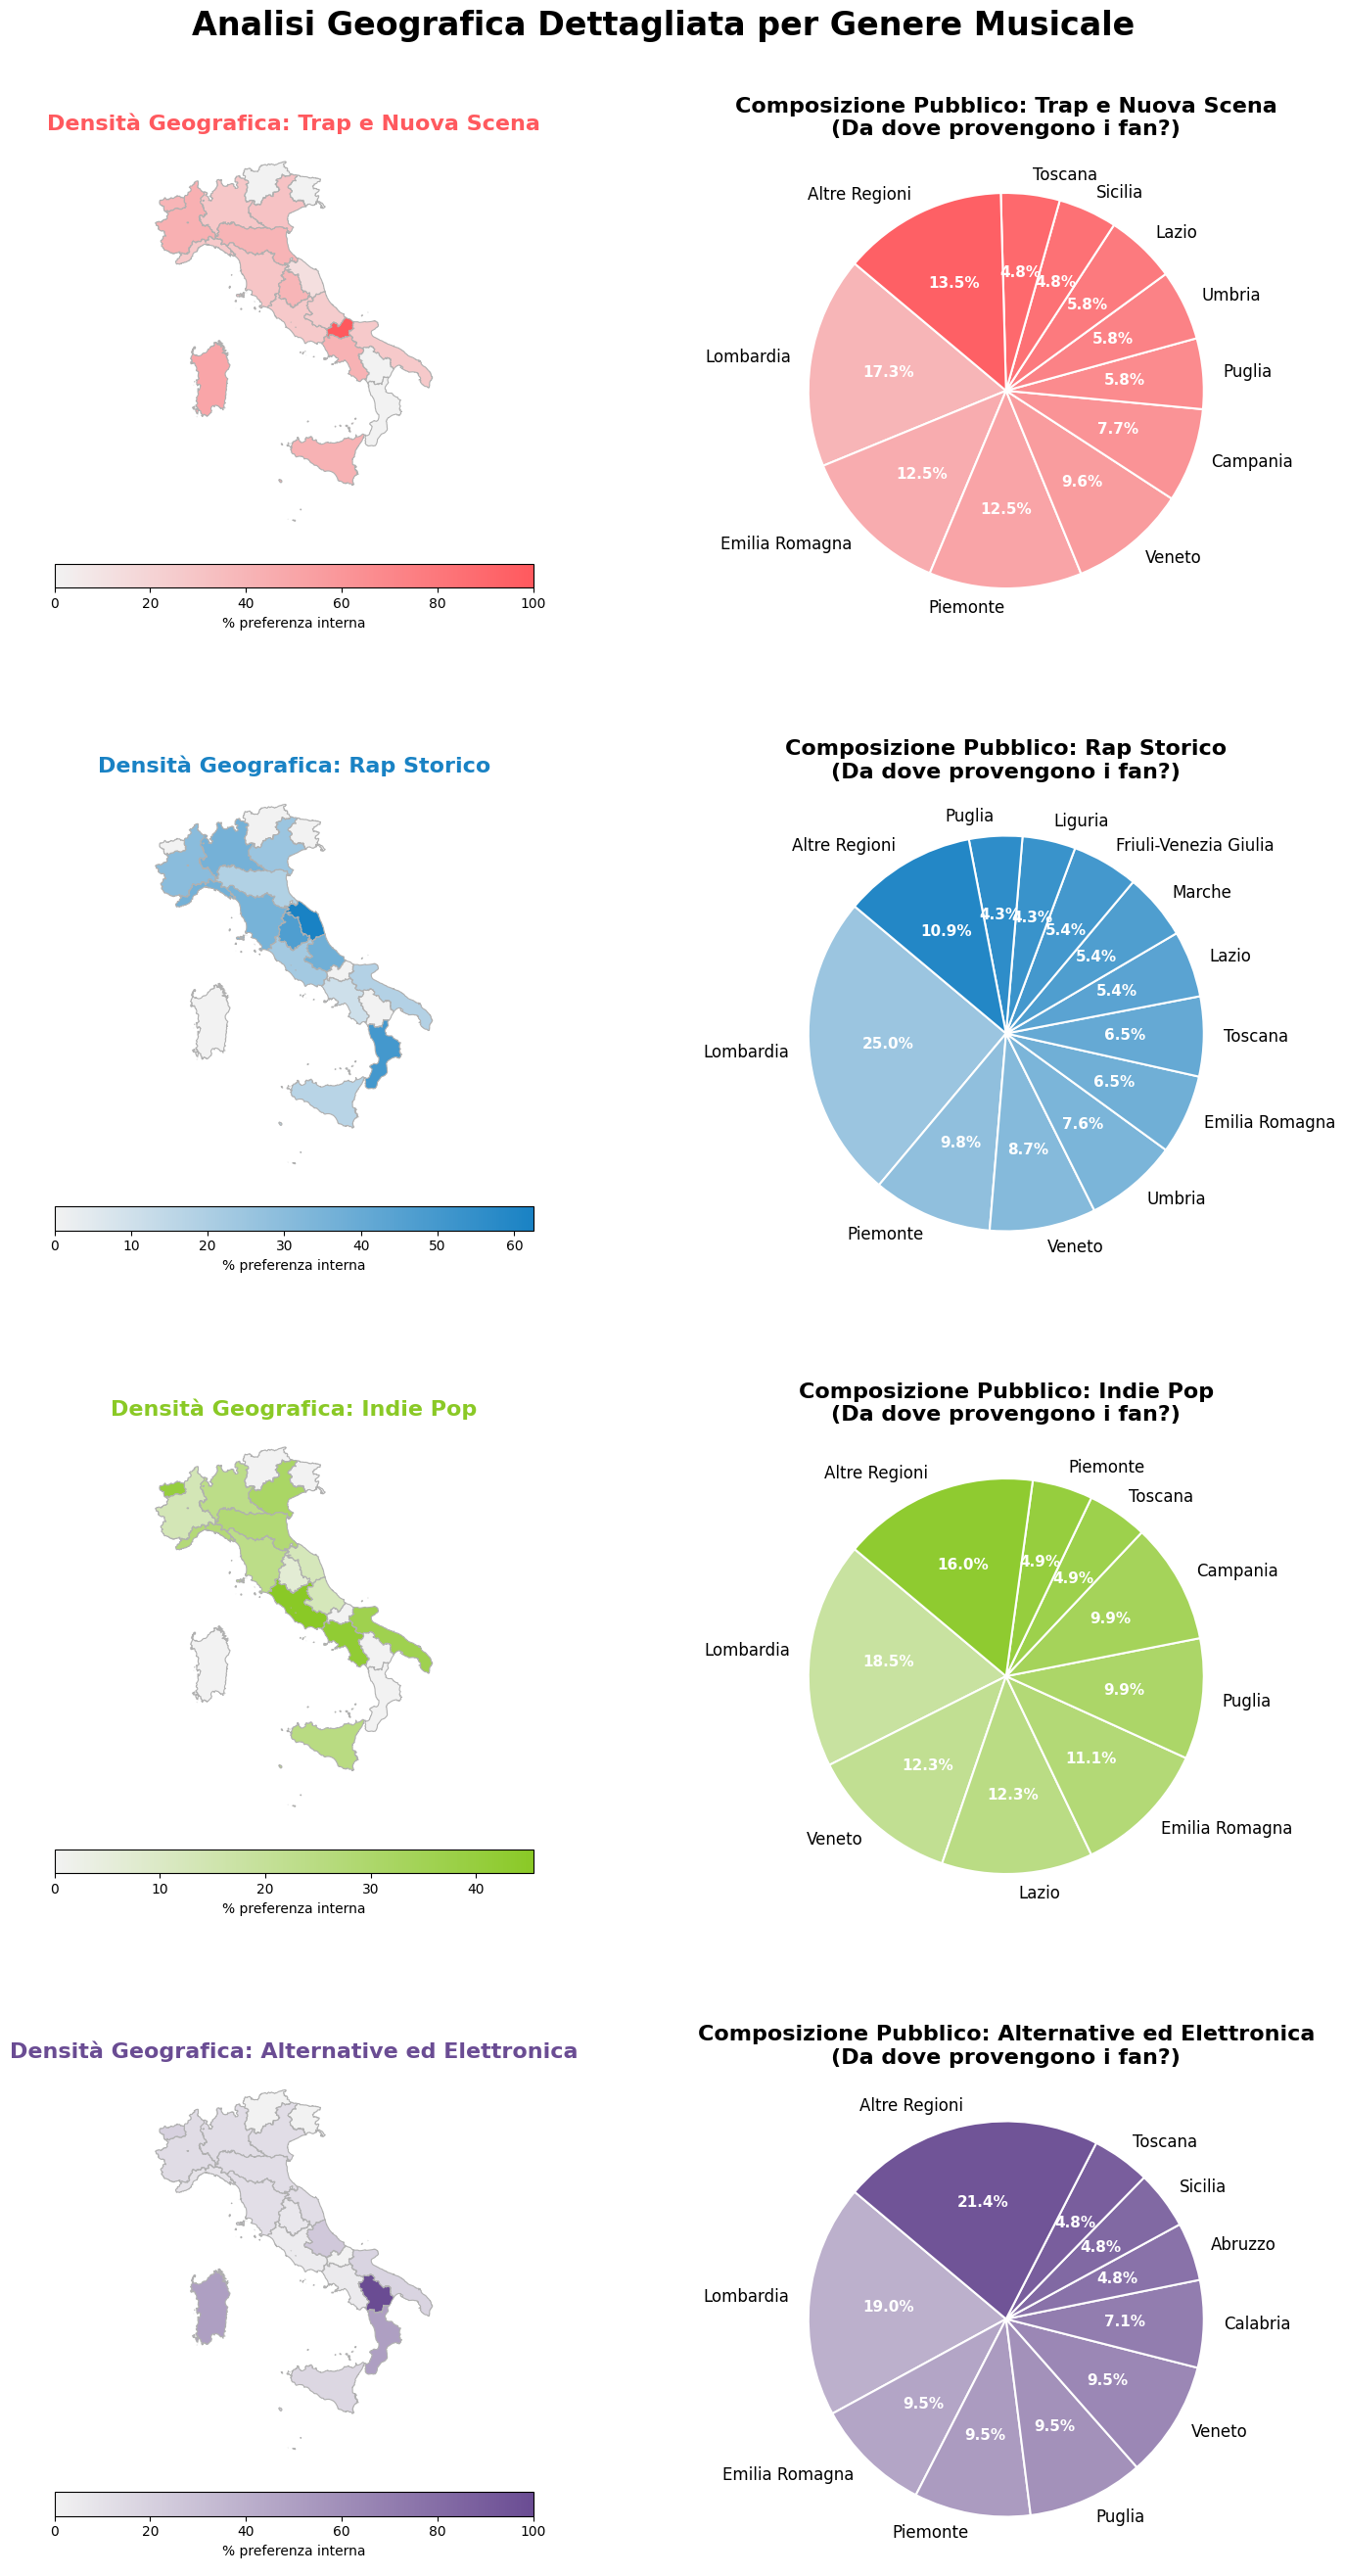

In [ ]:
# GRAFICI DISTRIBUZIONE GEOGRAFICA PER GENERE PREFERITO (VALORI RELATIVI)
from matplotlib.colors import LinearSegmentedColormap
base_colors = {
    'Trap_NuovaScena': '#FF595E',         # Rosso
    'Rap_Storico': '#1982C4',             # Blu
    'Indie_Pop': '#8AC926',               # Verde
    'Alternative_Elettronica': '#6A4C93'  # Viola
}

df_mappa = pd.read_csv('Mace.csv', sep=';', encoding='latin1')
target_col = 'Quale artista speri di vedere stasera?'

df_mappa['Cluster'] = df_mappa[target_col].map(cluster_mapping).fillna('Altro')
df_mappa = df_mappa[~df_mappa['Cluster'].isin(['Altro', 'Sconosciuto'])]
df_mappa = df_mappa[df_mappa['Da quale regione provieni?'].notna()]

perc_regioni_mappa = pd.crosstab(df_mappa['Da quale regione provieni?'], df_mappa['Cluster'], normalize='index') * 100
colonne_attese = ['Trap_NuovaScena', 'Rap_Storico', 'Indie_Pop', 'Alternative_Elettronica']
perc_regioni_mappa = perc_regioni_mappa.reindex(columns=colonne_attese, fill_value=0).reset_index()

url_geojson = 'https://raw.githubusercontent.com/openpolis/geojson-italy/master/geojson/limits_IT_regions.geojson'
italy = gpd.read_file(url_geojson)

mappa_nomi = {
    "Valle d'Aosta/Vallée d'Aoste": "Valle d'Aosta", "Trentino-Alto Adige/Südtirol": "Trentino Alto Adige",
    "Friuli-Venezia Giulia": "Friuli Venezia Giulia", "Emilia-Romagna": "Emilia Romagna",
    "Sicilia": "Sicilia", "Sardegna": "Sardegna", "Calabria": "Calabria",
    "Basilicata": "Basilicata", "Puglia": "Puglia", "Campania": "Campania",
    "Molise": "Molise", "Abruzzo": "Abruzzo", "Lazio": "Lazio",
    "Umbria": "Umbria", "Marche": "Marche", "Toscana": "Toscana",
    "Liguria": "Liguria", "Piemonte": "Piemonte", "Lombardia": "Lombardia", "Veneto": "Veneto"
}
italy['reg_name_clean'] = italy['reg_name'].map(lambda x: mappa_nomi.get(x, x))
mappa_completa = italy.merge(perc_regioni_mappa, left_on='reg_name_clean', right_on='Da quale regione provieni?', how='left')

configurazione_plot = [
    ('Trap_NuovaScena', 'Trap e Nuova Scena'),
    ('Rap_Storico', 'Rap Storico'),
    ('Indie_Pop', 'Indie Pop'),
    ('Alternative_Elettronica', 'Alternative ed Elettronica')
]

fig, axs = plt.subplots(4, 2, figsize=(16, 26))

for idx, (cluster_col, titolo_bello) in enumerate(configurazione_plot):
    ax_map = axs[idx, 0]
    ax_pie = axs[idx, 1]


    colore_base = base_colors[cluster_col]
    custom_cmap = LinearSegmentedColormap.from_list(f"cmap_{cluster_col}", ["#F2F2F2", colore_base])

    # MAPPA (Sinistra)
    mappa_completa[cluster_col] = mappa_completa[cluster_col].fillna(0)
    mappa_completa.plot(
        column=cluster_col, ax=ax_map, cmap=custom_cmap,
        linewidth=0.8, edgecolor='#B0B0B0', legend=True,
        legend_kwds={'label': f"% preferenza interna", 'orientation': "horizontal", 'shrink': 0.6, 'pad': 0.05}
    )
    ax_map.set_axis_off()
    ax_map.set_title(f"Densità Geografica: {titolo_bello}", fontsize=16, fontweight='bold', color=colore_base, pad=10)

    # TORTA (Destra)
    pubblico_genere = df_mappa[df_mappa['Cluster'] == cluster_col]

    if len(pubblico_genere) > 0:
        dati_torta = pubblico_genere['Da quale regione provieni?'].value_counts(normalize=True) * 100

        soglia = 4.0
        regioni_top = dati_torta[dati_torta >= soglia]
        regioni_altre = dati_torta[dati_torta < soglia].sum()
        if regioni_altre > 0:
            regioni_top['Altre Regioni'] = regioni_altre

        colori_torta = custom_cmap(np.linspace(0.4, 0.95, len(regioni_top)))

        wedges, texts, autotexts = ax_pie.pie(
            regioni_top, labels=regioni_top.index, autopct='%1.1f%%',
            startangle=140, colors=colori_torta,
            wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
        )

        plt.setp(autotexts, size=11, weight="bold", color="white")
        autotexts[-1].set_color('black') if len(regioni_top) > 1 and autotexts[-1].get_position()[0] > 0.5 else None

        plt.setp(texts, size=12)
        ax_pie.set_title(f"Composizione Pubblico: {titolo_bello}\n(Da dove provengono i fan?)", fontsize=16, fontweight='bold')
    else:
        ax_pie.text(0.5, 0.5, "Nessun dato disponibile", ha='center', va='center')
        ax_pie.set_axis_off()

plt.suptitle("Analisi Geografica Dettagliata per Genere Musicale", fontsize=24, fontweight='bold', y=1.01)
plt.tight_layout()
plt.subplots_adjust(hspace=0.3)
plt.show()

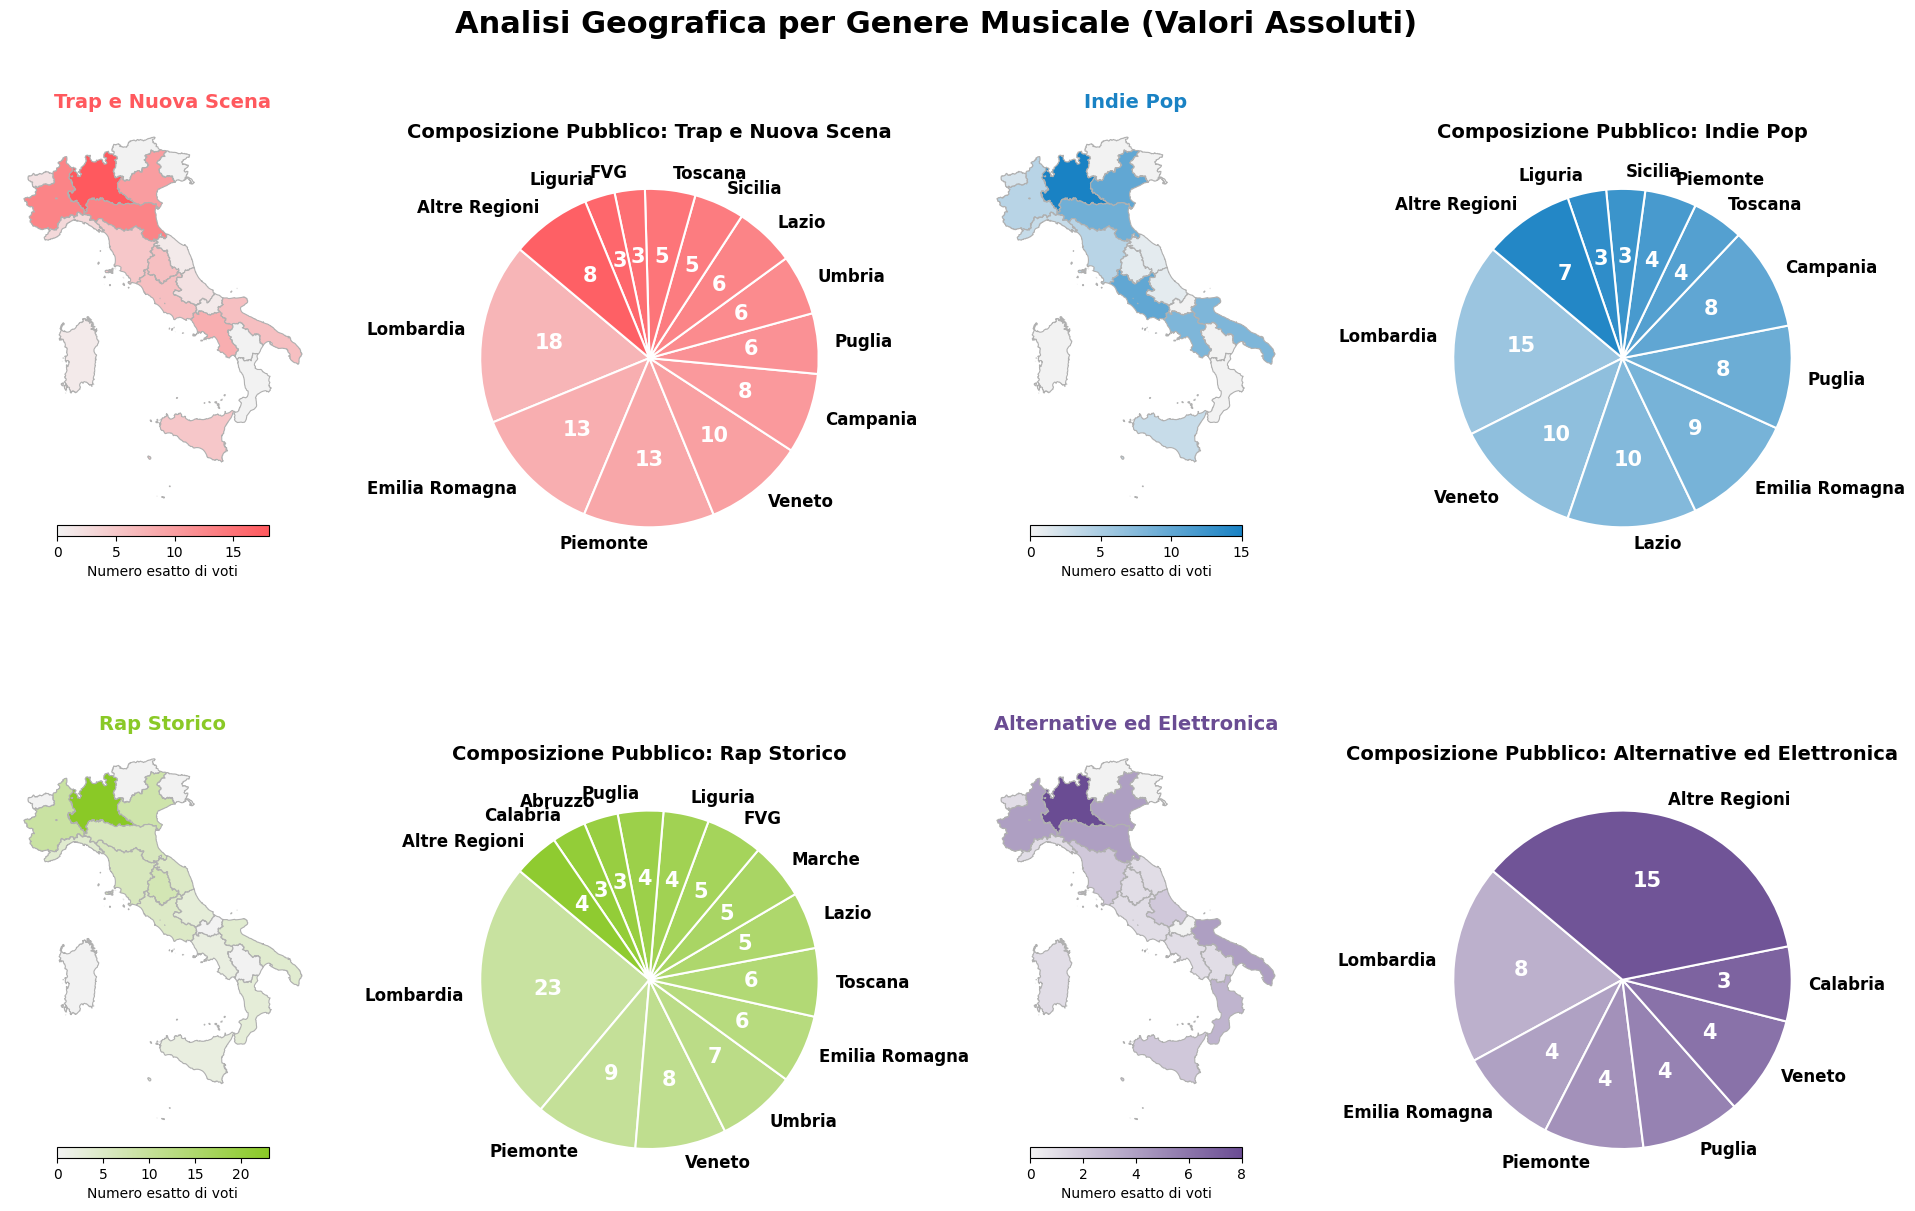

In [ ]:
# GRAFICI DISTRIBUZIONE GEOGRAFICA PER GENERE PREFERITO (VALORI ASSOLUTI)

# PALETTE
base_colors = {
    'Trap_NuovaScena': '#FF595E',          # Rosso
    'Rap_Storico': '#8AC926',              # VERDE
    'Indie_Pop': '#1982C4',                # CELESTE
    'Alternative_Elettronica': '#6A4C93'   # Viola
}

# DATI con CONTEGGI ASSOLUTI
df_mappa = pd.read_csv('Mace.csv', sep=';', encoding='latin1')
target_col = 'Quale artista speri di vedere stasera?'

df_mappa['Cluster'] = df_mappa[target_col].map(cluster_mapping).fillna('Altro')
df_mappa = df_mappa[~df_mappa['Cluster'].isin(['Altro', 'Sconosciuto'])]
df_mappa = df_mappa[df_mappa['Da quale regione provieni?'].notna()]

conteggi_regioni_mappa = pd.crosstab(df_mappa['Da quale regione provieni?'], df_mappa['Cluster'])
colonne_attese = ['Trap_NuovaScena', 'Rap_Storico', 'Indie_Pop', 'Alternative_Elettronica']
conteggi_regioni_mappa = conteggi_regioni_mappa.reindex(columns=colonne_attese, fill_value=0).reset_index()

url_geojson = 'https://raw.githubusercontent.com/openpolis/geojson-italy/master/geojson/limits_IT_regions.geojson'
italy = gpd.read_file(url_geojson)

mappa_nomi = {
    "Valle d'Aosta/Vallée d'Aoste": "Valle d'Aosta", "Trentino-Alto Adige/Südtirol": "Trentino Alto Adige",
    "Friuli-Venezia Giulia": "FVG", "Emilia-Romagna": "Emilia Romagna",
    "Sicilia": "Sicilia", "Sardegna": "Sardegna", "Calabria": "Calabria",
    "Basilicata": "Basilicata", "Puglia": "Puglia", "Campania": "Campania",
    "Molise": "Molise", "Abruzzo": "Abruzzo", "Lazio": "Lazio",
    "Umbria": "Umbria", "Marche": "Marche", "Toscana": "Toscana",
    "Liguria": "Liguria", "Piemonte": "Piemonte", "Lombardia": "Lombardia", "Veneto": "Veneto"
}
italy['reg_name_clean'] = italy['reg_name'].map(lambda x: mappa_nomi.get(x, x))
mappa_completa = italy.merge(conteggi_regioni_mappa, left_on='reg_name_clean', right_on='Da quale regione provieni?', how='left')

# DISEGNO DELLA GRIGLIA 2x2
configurazione_plot = [
    ('Trap_NuovaScena', 'Trap e Nuova Scena'),
    ('Indie_Pop', 'Indie Pop'),
    ('Rap_Storico', 'Rap Storico'),
    ('Alternative_Elettronica', 'Alternative ed Elettronica')
]

fig, axs = plt.subplots(2, 4, figsize=(20, 12))
for idx, (cluster_col, titolo_bello) in enumerate(configurazione_plot):
    riga = idx // 2
    colonna = idx % 2
    ax_map = axs[riga, colonna * 2]
    ax_pie = axs[riga, colonna * 2 + 1]
    colore_base = base_colors[cluster_col]
    custom_cmap = LinearSegmentedColormap.from_list(f"cmap_{cluster_col}", ["#F2F2F2", colore_base])

    # MAPPA (Sinistra)
    mappa_completa[cluster_col] = mappa_completa[cluster_col].fillna(0)
    mappa_completa.plot(
        column=cluster_col, ax=ax_map, cmap=custom_cmap,
        linewidth=0.8, edgecolor='#B0B0B0', legend=True,
        legend_kwds={'label': f"Numero esatto di voti", 'orientation': "horizontal", 'shrink': 0.5, 'pad': 0.02}
    )
    ax_map.set_axis_off()
    ax_map.set_title(f"{titolo_bello}", fontsize=14, fontweight='bold', color=colore_base, pad=8)

    # TORTA (Destra)
    pubblico_genere = df_mappa[df_mappa['Cluster'] == cluster_col]

    if len(pubblico_genere) > 0:
        dati_torta = pubblico_genere['Da quale regione provieni?'].value_counts()

        soglia = 3
        regioni_top = dati_torta[dati_torta >= soglia]
        regioni_altre = dati_torta[dati_torta < soglia].sum()
        if regioni_altre > 0:
            regioni_top['Altre Regioni'] = regioni_altre

        # Friuli Venezia Giulia rinominato in FV
        regioni_top.index = regioni_top.index.map(lambda x: 'FVG' if x == 'Friuli-Venezia Giulia' else x)

        colori_torta = custom_cmap(np.linspace(0.4, 0.95, len(regioni_top)))

        formato_numero = lambda p: f"{int(round(p * sum(regioni_top) / 100.0))}"

        wedges, texts, autotexts = ax_pie.pie(
            regioni_top, labels=regioni_top.index,
            autopct=formato_numero,
            startangle=140, colors=colori_torta,
            wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
        )

        plt.setp(autotexts, size=15, weight="bold", color="white")
        if len(regioni_top) > 1 and autotexts[-1].get_position()[0] > 0.5:
            autotexts[-1].set_color('black')

        plt.setp(texts, size=12, weight="bold")
        ax_pie.set_title(f"Composizione Pubblico: {titolo_bello}", fontsize=14, fontweight='bold')
    else:
        ax_pie.text(0.5, 0.5, "Nessun dato disponibile", ha='center', va='center')
        ax_pie.set_axis_off()

plt.suptitle("Analisi Geografica per Genere Musicale (Valori Assoluti)", fontsize=22, fontweight='bold', y=1.02)
plt.tight_layout()
plt.subplots_adjust(hspace=0.3, wspace=0.15)
plt.show()


🗺️ Generazione Plancia: Dati Normalizzati con Soglia Statistica (Min. 10 intervistati)...


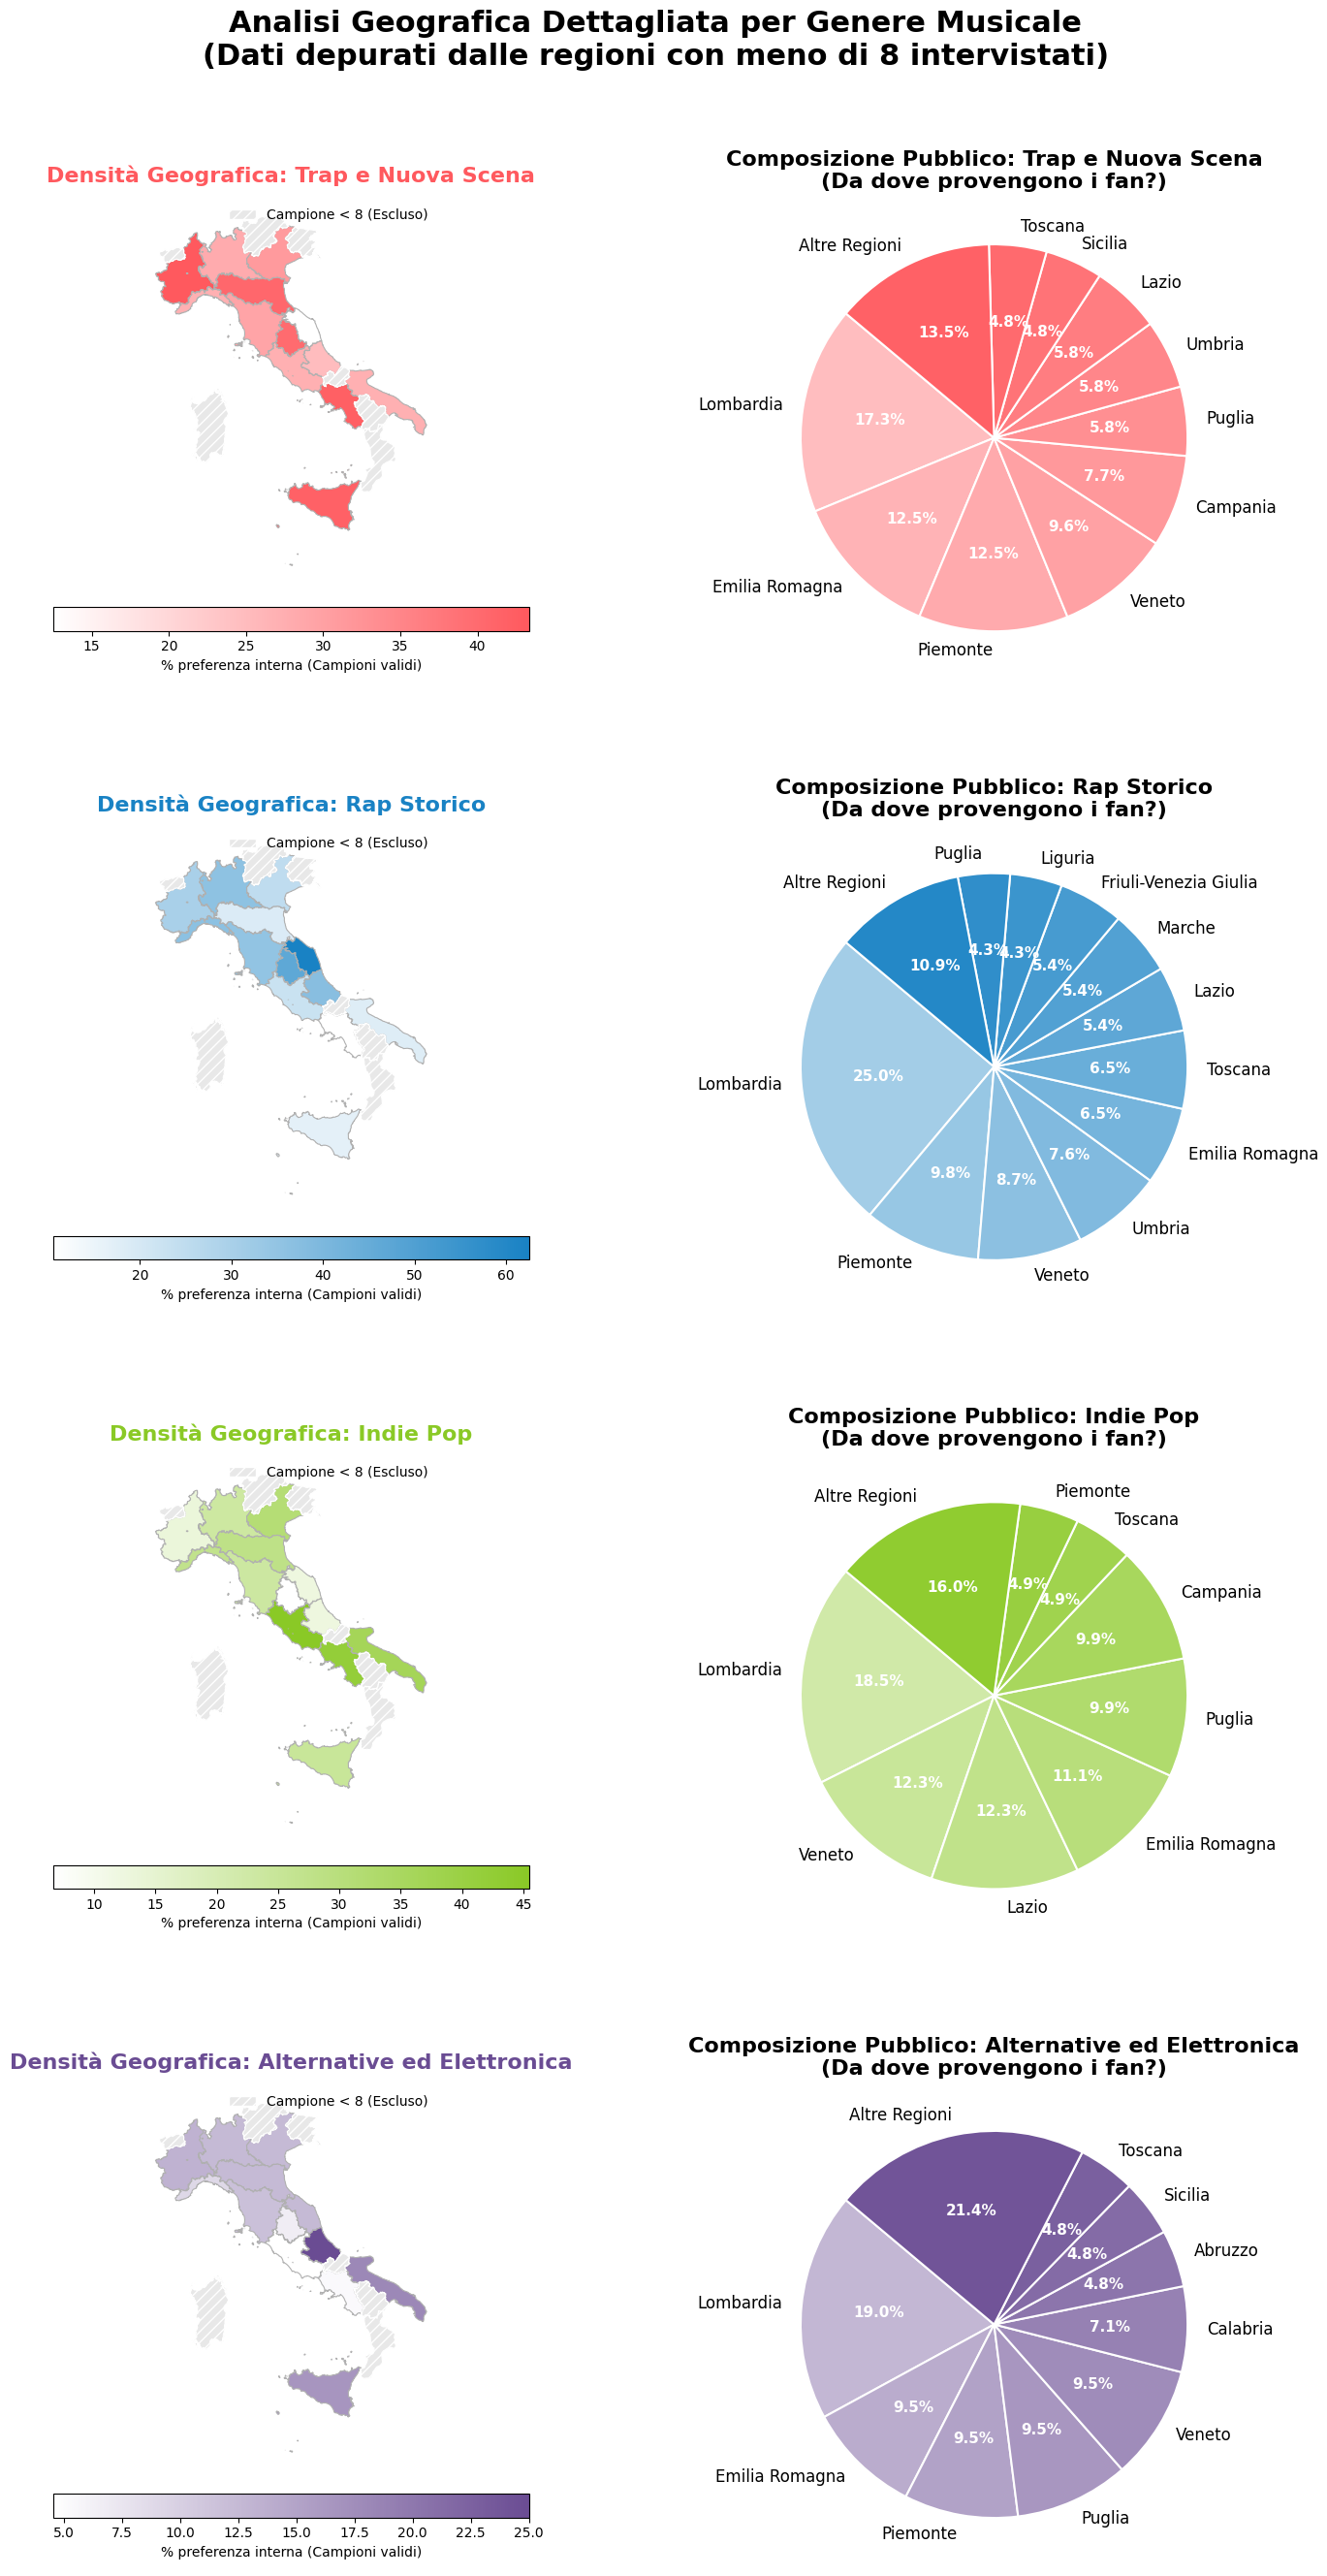

In [ ]:
# GRAFICI DISTRIBUZIONE GEOGRAFICA CON SOGLIA DI AFFIDABILITÀ
import matplotlib.patches as mpatches

print("\n🗺️ Generazione Plancia: Dati Normalizzati con Soglia Statistica (Min. 10 intervistati)...")

#palette

base_colors = {
    'Trap_NuovaScena': '#FF595E',
    'Rap_Storico': '#1982C4',
    'Indie_Pop': '#8AC926',
    'Alternative_Elettronica': '#6A4C93'
}

#applicazione soglia per tenere le regioni
SOGLIA_MINIMA = 8

df_mappa = pd.read_csv('Mace.csv', sep=';', encoding='latin1')
target_col = 'Quale artista speri di vedere stasera?'

df_mappa['Cluster'] = df_mappa[target_col].map(cluster_mapping).fillna('Altro')
df_mappa = df_mappa[~df_mappa['Cluster'].isin(['Altro', 'Sconosciuto'])]
df_mappa = df_mappa[df_mappa['Da quale regione provieni?'].notna()]

# n°intervistati per regione
conteggi_regioni = df_mappa['Da quale regione provieni?'].value_counts()
regioni_valide = conteggi_regioni[conteggi_regioni >= SOGLIA_MINIMA].index.tolist()

# percentuali (normalizzate)
perc_regioni_mappa = pd.crosstab(df_mappa['Da quale regione provieni?'], df_mappa['Cluster'], normalize='index') * 100
colonne_attese = ['Trap_NuovaScena', 'Rap_Storico', 'Indie_Pop', 'Alternative_Elettronica']
perc_regioni_mappa = perc_regioni_mappa.reindex(columns=colonne_attese, fill_value=0)

# Se la regione non ha almeno 8 persone, annulliamo il dato (NaN)
perc_regioni_mappa.loc[~perc_regioni_mappa.index.isin(regioni_valide), :] = np.nan
perc_regioni_mappa = perc_regioni_mappa.reset_index()

url_geojson = 'https://raw.githubusercontent.com/openpolis/geojson-italy/master/geojson/limits_IT_regions.geojson'
italy = gpd.read_file(url_geojson)

mappa_nomi = {
    "Valle d'Aosta/Vallée d'Aoste": "Valle d'Aosta", "Trentino-Alto Adige/Südtirol": "Trentino Alto Adige",
    "Friuli-Venezia Giulia": "Friuli Venezia Giulia", "Emilia-Romagna": "Emilia Romagna"
}
italy['reg_name_clean'] = italy['reg_name'].map(lambda x: mappa_nomi.get(x, x))
mappa_completa = italy.merge(perc_regioni_mappa, left_on='reg_name_clean', right_on='Da quale regione provieni?', how='left')


configurazione_plot = [
    ('Trap_NuovaScena', 'Trap e Nuova Scena'),
    ('Rap_Storico', 'Rap Storico'),
    ('Indie_Pop', 'Indie Pop'),
    ('Alternative_Elettronica', 'Alternative ed Elettronica')
]

fig, axs = plt.subplots(4, 2, figsize=(16, 26))

for idx, (cluster_col, titolo_bello) in enumerate(configurazione_plot):
    ax_map = axs[idx, 0]
    ax_pie = axs[idx, 1]

    colore_base = base_colors[cluster_col]
    custom_cmap = LinearSegmentedColormap.from_list(f"cmap_{cluster_col}", ["#FFFFFF", colore_base])

    #  MAPPA (Sinistra)
    # Le regioni senza dati validi (NaN) vengono disegnate in grigio chiaro con un tratteggio
    mappa_completa.plot(
        column=cluster_col, ax=ax_map, cmap=custom_cmap,
        linewidth=0.8, edgecolor='#B0B0B0', legend=True,
        missing_kwds={"color": "#E8E8E8", "hatch": "///", "edgecolor": "white"},
        legend_kwds={'label': f"% preferenza interna (Campioni validi)", 'orientation': "horizontal", 'shrink': 0.6, 'pad': 0.05}
    )
    ax_map.set_axis_off()
    ax_map.set_title(f"Densità Geografica: {titolo_bello}", fontsize=16, fontweight='bold', color=colore_base, pad=10)

    # legenda
    campione_insufficiente_patch = mpatches.Patch(facecolor='#E8E8E8', hatch='///', edgecolor='white', label='Campione < 8 (Escluso)')
    ax_map.legend(handles=[campione_insufficiente_patch], loc='upper right', fontsize=10, frameon=False)

    # TORTA (Destra) - Rimane invariata sui volumi totali
    pubblico_genere = df_mappa[df_mappa['Cluster'] == cluster_col]

    if len(pubblico_genere) > 0:
        dati_torta = pubblico_genere['Da quale regione provieni?'].value_counts(normalize=True) * 100

        soglia = 4.0
        regioni_top = dati_torta[dati_torta >= soglia]
        regioni_altre = dati_torta[dati_torta < soglia].sum()
        if regioni_altre > 0:
            regioni_top['Altre Regioni'] = regioni_altre

        colori_torta = custom_cmap(np.linspace(0.4, 0.95, len(regioni_top)))

        wedges, texts, autotexts = ax_pie.pie(
            regioni_top, labels=regioni_top.index, autopct='%1.1f%%',
            startangle=140, colors=colori_torta,
            wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
        )

        plt.setp(autotexts, size=11, weight="bold", color="white")
        autotexts[-1].set_color('black') if len(regioni_top) > 1 and autotexts[-1].get_position()[0] > 0.5 else None
        plt.setp(texts, size=12)
        ax_pie.set_title(f"Composizione Pubblico: {titolo_bello}\n(Da dove provengono i fan?)", fontsize=16, fontweight='bold')
    else:
        ax_pie.text(0.5, 0.5, "Nessun dato disponibile", ha='center', va='center')
        ax_pie.set_axis_off()

plt.suptitle("Analisi Geografica Dettagliata per Genere Musicale\n(Dati depurati dalle regioni con meno di 8 intervistati)", fontsize=22, fontweight='bold', y=1.02)
plt.tight_layout()
plt.subplots_adjust(hspace=0.3)
plt.show()

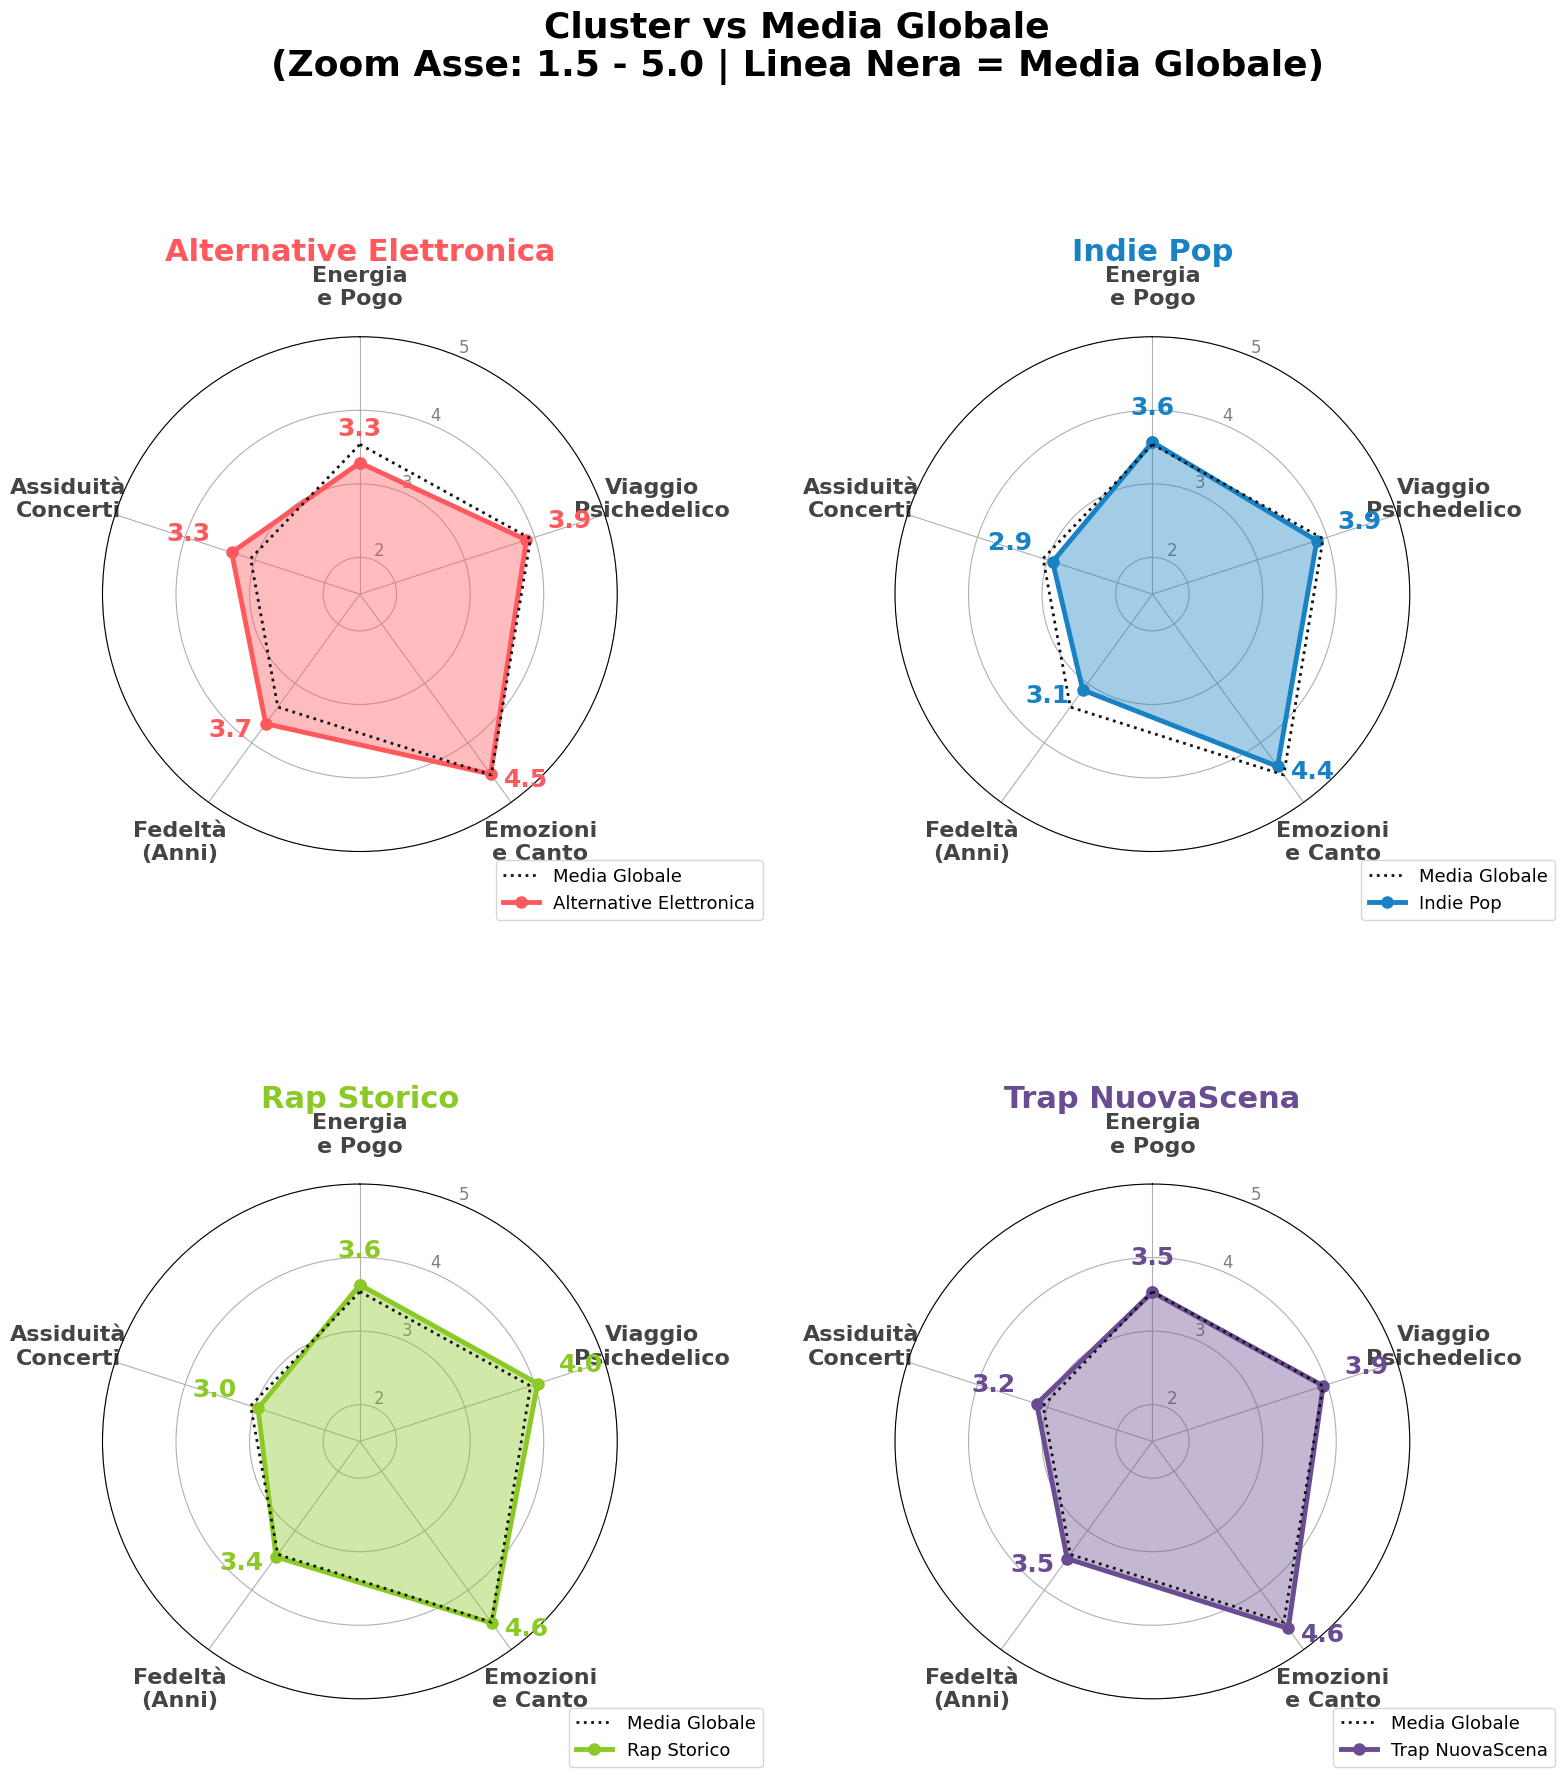

In [ ]:
# GRAFICO A RAGNATELA (RADAR CHART)
df_radar_viz = df.copy()

# nomi dei cluster
radar_clusters_def = {
    'Trap_NuovaScena': ['Izi', 'Kid Yugi', 'Tony Boy', 'Astro', 'Geolier', 'Samurai Jay', 'Ketama126', 'Ele A'],
    'Rap_Storico': ['Gemitaiz', 'Salmo', 'Fabri Fibra', 'Noyz Narcos', 'Gué', 'Jake la Furia'],
    'Indie_Pop': ['Frah Quintale', 'Marco Mengoni', 'Centomilacarie', 'Franco126', 'Marco Castello', 'Chiello', 'Madame', 'Blanco', 'Psicologi', 'Rkomi', 'Fulminacci', 'Rosa Chemical', 'Colapesce'],
    'Alternative_Elettronica': ['Venerus', 'Cosmo', 'Joan Thiele', 'Altea']
}

# dizionario inverso per mappare qualsiasi nome al suo Cluster
radar_reverse_map = {}
for r_cluster_name, r_artists in radar_clusters_def.items():
    for r_artist in r_artists:
        radar_reverse_map[r_artist] = r_cluster_name

# Applichiamo la mappatura in una colonna nuova dedicata solo al grafico
df_radar_viz['Radar_Cluster'] = df_radar_viz['Quale artista speri di vedere stasera?'].map(radar_reverse_map).fillna('Altro')
df_radar_viz = df_radar_viz[df_radar_viz['Radar_Cluster'] != 'Altro']

# Trasformazione delle variabili fisse
radar_ascolto_col = [c for c in df_radar_viz.columns if 'ascolti regolarmente' in c.lower()][0]
radar_map_anni = {'Meno di un anno': 1, '1-2 anni': 2.5, '3-4 anni': 4, 'Più di 5 anni': 5}
df_radar_viz['Radar_Fedeltà'] = df_radar_viz[radar_ascolto_col].map(radar_map_anni).fillna(2.5)
df_radar_viz['Radar_Assiduità'] = pd.to_numeric(df_radar_viz['A quanti concerti assisti in un anno?'], errors='coerce').clip(upper=5).fillna(2)

radar_cols = [
    'Cosa cerchi nel concerto? [Energia e Pogo]',
    'Cosa cerchi nel concerto? [Viaggio Psichedelico]',
    'Cosa cerchi nel concerto? [Emozioni e canto a squarciagola]',
    'Radar_Fedeltà',
    'Radar_Assiduità'
]
radar_labels = ['Energia\ne Pogo', 'Viaggio\nPsichedelico', 'Emozioni\ne Canto', 'Fedeltà\n(Anni)', 'Assiduità\nConcerti']

# Calcolo Medie
radar_global_mean = df_radar_viz[radar_cols].mean().tolist()
radar_global_mean += radar_global_mean[:1]
radar_cluster_means = df_radar_viz.groupby('Radar_Cluster')[radar_cols].mean()

# Creazione Grafico (Matrice 2x2)
radar_angles = np.linspace(0, 2 * np.pi, len(radar_labels), endpoint=False).tolist()
radar_angles += radar_angles[:1]

radar_fig, radar_axs = plt.subplots(2, 2, figsize=(16, 18), subplot_kw=dict(polar=True))
radar_axs = radar_axs.flatten()

radar_colors = ['#FF595E', '#1982C4', '#8AC926', '#6A4C93']

for radar_idx, (r_cluster_name, r_row) in enumerate(radar_cluster_means.iterrows()):
    r_ax = radar_axs[radar_idx]
    r_values = r_row.tolist()
    r_values += r_values[:1]

    # Media globale (wireframe)
    r_ax.plot(radar_angles, radar_global_mean, color='#111111', linewidth=2, linestyle=':', zorder=10, label='Media Globale')

    # Cluster specifico
    r_color = radar_colors[radar_idx]
    r_ax.plot(radar_angles, r_values, color=r_color, linewidth=3.5, marker='o', markersize=8, zorder=5, label=r_cluster_name.replace('_', ' '))
    r_ax.fill(radar_angles, r_values, color=r_color, alpha=0.4, zorder=4)

    # Zoom e Impostazioni Assi
    r_ax.set_ylim(1.5, 5)
    r_ax.set_yticks([2, 3, 4, 5])
    r_ax.set_yticklabels(['2', '3', '4', '5'], color="grey", size=12)

    r_ax.set_theta_offset(np.pi / 2)
    r_ax.set_theta_direction(-1)
    r_ax.set_xticks(radar_angles[:-1])
    r_ax.set_xticklabels(radar_labels, fontsize=16, weight='bold', color='#444444')
    r_ax.tick_params(axis='x', pad=25)

    for r_i in range(len(radar_labels)):
        r_angle_rad = radar_angles[r_i]
        r_val_cluster = r_values[r_i]

        r_ha = 'center'
        r_va = 'bottom'
        if r_angle_rad > 0 and r_angle_rad < np.pi: r_ha = 'left'
        elif r_angle_rad > np.pi: r_ha = 'right'

        r_ax.text(r_angle_rad, r_val_cluster + 0.3, f"{r_val_cluster:.1f}",
                color=r_color, weight='bold', size=18, ha=r_ha, va=r_va)

    r_ax.set_title(r_cluster_name.replace('_', ' '), size=22, weight='bold', color=r_color, pad=55)
    r_ax.legend(loc='lower right', bbox_to_anchor=(1.30, -0.15), fontsize=13)

plt.subplots_adjust(hspace=0.2, wspace=0.05)
plt.suptitle('Cluster vs Media Globale\n(Zoom Asse: 1.5 - 5.0 | Linea Nera = Media Globale)', size=26, weight='bold', y=1.03)

plt.tight_layout()
plt.show()

In [ ]:
# CONTEGGIO NUMERICO DATI PER TABELLE

from IPython.display import display
df_raw = pd.read_csv('Mace.csv', sep=';', encoding='latin1')

# Pulizia età
df_raw['Quanti anni hai?'] = pd.to_numeric(df_raw['Quanti anni hai?'], errors='coerce')
df_eta_pulita = df_raw.dropna(subset=['Quanti anni hai?']).copy()

#CONTEGGIO PER SINGOLA ETÀ
tabella_eta = df_eta_pulita['Quanti anni hai?'].value_counts().reset_index()
tabella_eta.columns = ['Età', 'Numero di Individui']

# Ordiniamo e togliamo i decimali
tabella_eta = tabella_eta.sort_values(by='Età').reset_index(drop=True)
tabella_eta['Età'] = tabella_eta['Età'].astype(int).astype(str) # Convertiamo in stringa per poter aggiungere la scritta del totale

# Aggiunta riga Totale Età
totale_eta = tabella_eta['Numero di Individui'].sum()
riga_totale_eta = pd.DataFrame([{'Età': 'TOTALE COMPLESSIVO', 'Numero di Individui': totale_eta}])
tabella_eta = pd.concat([tabella_eta, riga_totale_eta], ignore_index=True)


# CONTEGGIO PER SINGOLA REGIONE
# Rimuoviamo chi non ha specificato la regione
df_regioni = df_raw[~df_raw['Da quale regione provieni?'].isin(['Sconosciuto', None])].copy()

tabella_regioni = df_regioni['Da quale regione provieni?'].value_counts().reset_index()
tabella_regioni.columns = ['Regione', 'Numero di Individui']

# Aggiunta riga Totale Regioni
totale_regioni = tabella_regioni['Numero di Individui'].sum()
riga_totale_regioni = pd.DataFrame([{'Regione': 'TOTALE COMPLESSIVO', 'Numero di Individui': totale_regioni}])
tabella_regioni = pd.concat([tabella_regioni, riga_totale_regioni], ignore_index=True)

#tabelle
print("CONTEGGIO PER SINGOLA ETÀ:")
display(tabella_eta)

print("CONTEGGIO PER SINGOLA REGIONE:")
display(tabella_regioni)
print("CONTEGGIO DEGLI INDIVIDUI PER GENERE...\n")

# RECUPERO DATI ORIGINALI
# Ricarichiamo il dataset originale per sicurezza
df_raw = pd.read_csv('Mace.csv', sep=';', encoding='latin1')

# Assicuriamoci che la colonna esista e rimuoviamo chi non ha risposto alla domanda
colonna_genere = 'Qual è il tuo genere?'
df_genere = df_raw.dropna(subset=[colonna_genere]).copy()

# CONTEGGIO ESATTO
# Contiamo tutte le voci presenti
tabella_genere = df_genere[colonna_genere].value_counts().reset_index()
tabella_genere.columns = ['Genere', 'Numero di Individui']

# Calcoliamo anche il totale generale per comodità e lo aggiungiamo in fondo
totale_individui = tabella_genere['Numero di Individui'].sum()
riga_totale = pd.DataFrame([{'Genere': 'TOTALE COMPLESSIVO', 'Numero di Individui': totale_individui}])
tabella_genere = pd.concat([tabella_genere, riga_totale], ignore_index=True)

display(tabella_genere)

# riscrittura modalità
aspettative = {
    'Cosa cerchi nel concerto? [Energia e Pogo]': 'Energia e Pogo',
    'Cosa cerchi nel concerto? [Emozioni e canto a squarciagola]': 'Emozioni e Canto',
    'Cosa cerchi nel concerto? [Viaggio Psichedelico]': 'Viaggio Psichedelico'
}

tabelle_parziali = []

for colonna_originale, nome_breve in aspettative.items():
    # Puliamo i dati rimuovendo chi non ha risposto a quella specifica domanda
    df_temp = df_radar_viz.dropna(subset=[colonna_originale, 'Radar_Cluster']).copy()
    df_temp[colonna_originale] = pd.to_numeric(df_temp[colonna_originale], errors='coerce').astype(int)

    # Creiamo la tabella base (Cluster vs Voti 1-5)
    tab = pd.crosstab(index=df_temp['Radar_Cluster'], columns=df_temp[colonna_originale])

    # Calcoliamo matematicamente la colonna dei Totali
    tab['TOTALE INTERVISTATI'] = tab.sum(axis=1)

    # Assegniamo l'etichetta dell'aspettativa
    tab['Aspettativa'] = nome_breve

    # trasformiamo 'Cluster' e 'Aspettativa' in un Indice Multiplo
    tab = tab.reset_index().set_index(['Radar_Cluster', 'Aspettativa'])

    tabelle_parziali.append(tab)

tabella_unica = pd.concat(tabelle_parziali)
tabella_unica = tabella_unica.sort_index(level=0)
tabella_unica.columns.name = 'Voti Dati (1-5)'

display(tabella_unica)

# Usiamo il nome esatto della colonna che contiene i cluster
colonna_cluster = 'Quale artista speri di vedere stasera?'

# Pulizia preliminare: filtriamo le voci non valide e gli "Sconosciuto"
df_valido = df.dropna(subset=['Da quale regione provieni?', colonna_cluster])
df_valido = df_valido[df_valido['Da quale regione provieni?'] != 'Sconosciuto']
df_valido = df_valido[~df_valido[colonna_cluster].isin(['Altro', 'Sconosciuto'])]

# Creazione della Tabella Incrociata
tabella_regioni = pd.crosstab(
    index=df_valido['Da quale regione provieni?'],
    columns=df_valido[colonna_cluster],
    margins=True,
    margins_name='Totale Complessivo'
)

# regioni con più partecipanti in alto
tabella_ordinata = tabella_regioni.drop('Totale Complessivo').sort_values(by='Totale Complessivo', ascending=False)
tabella_ordinata.loc['Totale Complessivo'] = tabella_regioni.loc['Totale Complessivo']

rinomina_colonne = {
    'Alternative_Elettronica': 'Alt. Elettronica',
    'Indie_Pop': 'Indie Pop',
    'Rap_Storico': 'Rap Storico',
    'Trap_NuovaScena': 'Trap Nuova Scena'
}
tabella_ordinata = tabella_ordinata.rename(columns=rinomina_colonne)
display(tabella_ordinata)

CONTEGGIO PER SINGOLA ETÀ:


,Età,Numero di Individui
0,15,1
1,16,1
2,17,8
3,18,22
4,19,47
5,20,74
6,21,51
7,22,30
8,23,19
9,24,18


CONTEGGIO PER SINGOLA REGIONE:


,Regione,Numero di Individui
0,Lombardia,64
1,Emilia Romagna,32
2,Veneto,32
3,Piemonte,30
4,Lazio,22
5,Puglia,22
6,Campania,19
7,Toscana,17
8,Umbria,15
9,Sicilia,12


CONTEGGIO DEGLI INDIVIDUI PER GENERE...



,Genere,Numero di Individui
0,Donna,182
1,Uomo,133
2,Altro,4
3,TOTALE COMPLESSIVO,319


Voti Dati (1-5)                               1   2   3   4   5  \
Radar_Cluster           Aspettativa                               
Alternative_Elettronica Emozioni e Canto      0   1   4   9  28   
                        Energia e Pogo        4   8  12   8  10   
                        Viaggio Psichedelico  2   2  11  11  16   
Indie_Pop               Emozioni e Canto      2   1   8  22  48   
                        Energia e Pogo        4  10  22  26  19   
                        Viaggio Psichedelico  5  11  11  18  36   
Rap_Storico             Emozioni e Canto      0   2   6  23  61   
                        Energia e Pogo        4  12  28  18  30   
                        Viaggio Psichedelico  2   6  16  30  38   
Trap_NuovaScena         Emozioni e Canto      1   1   8  14  80   
                        Energia e Pogo        8  16  22  29  29   
                        Viaggio Psichedelico  5  10  16  28  45   

Voti Dati (1-5)                               TOTALE INTERVISTATI  
Radar_Cluster           Aspettativa                                
Alternative_Elettronica Emozioni e Canto                       42  
                        Energia e Pogo                         42  
                        Viaggio Psichedelico                   42  
Indie_Pop               Emozioni e Canto                       81  
                        Energia e Pogo                         81  
                        Viaggio Psichedelico                   81  
Rap_Storico             Emozioni e Canto                       92  
                        Energia e Pogo                         92  
                        Viaggio Psichedelico                   92  
Trap_NuovaScena         Emozioni e Canto                      104  
                        Energia e Pogo                        104  
                        Viaggio Psichedelico                  104

Quale artista speri di vedere stasera?,Frah Quintale,Gemitaiz,Izi,Venerus,Totale Complessivo
Da quale regione provieni?,,,,,
Lombardia,15,23,18,8,64
Emilia Romagna,9,6,13,4,32
Veneto,10,8,10,4,32
Piemonte,4,9,13,4,30
Puglia,8,4,6,4,22
Lazio,10,5,6,1,22
Campania,8,2,8,1,19
Toscana,4,6,5,2,17
Umbria,1,7,6,1,15


##Preprocessing dei dati

In [ ]:
# DATA CLEANING & FEATURE ENGINEERING
nord = ['Lombardia', 'Emilia Romagna', 'Veneto', 'Piemonte', 'Liguria', 'Friuli Venezia Giulia', 'Friuli-Venezia Giulia', 'Trentino Alto Adige', 'Trentino-Alto Adige', "Valle d'Aosta", "Valle D'Aosta"]
centro = ['Lazio', 'Toscana', 'Umbria', 'Marche']
sud_isole = ['Campania', 'Puglia', 'Sicilia', 'Calabria', 'Sardegna', 'Basilicata', 'Abruzzo', 'Molise'] #prima stavano qua molise e abruzzo -> 42.19%

def map_regione(r):
    if pd.isna(r) or r == 'Sconosciuto': return 'Sconosciuto'
    r_strip = r.strip()
    if r_strip in nord: return 'Nord'
    if r_strip in centro: return 'Centro'
    if r_strip in sud_isole: return 'Sud e Isole'
    return 'Altro'

df['Da quale regione provieni?'] = df['Da quale regione provieni?'].apply(map_regione)

main_words = ['Psichedelico', 'Emozionale', 'Energetico', 'Tecnico']
df['Quale parola descrive meglio Mace secondo te?'] = df['Quale parola descrive meglio Mace secondo te?'].apply(
    lambda x: x if x in main_words else 'Altro'
)

df['Cosa hai bevuto stasera?'] = df['Cosa hai bevuto stasera?'].map(
    {'Acqua/Nulla': 'Analcolico', 'Birra': 'Alcolico', 'Spritzzzzzzz': 'Alcolico', 'Vino': 'Alcolico'}
).fillna('Sconosciuto')

years_map = {'Meno di un anno': 0, '1-2 anni': 1, '3-4 anni': 2, 'Più di 5 anni': 3}
df['Da quanti anni ascolti regolarmente Mace?'] = df['Da quanti anni ascolti regolarmente Mace?'].map(years_map)
df['Da quanti anni ascolti regolarmente Mace?'] = df['Da quanti anni ascolti regolarmente Mace?'].fillna(df['Da quanti anni ascolti regolarmente Mace?'].median())

# GESTIONE ETÀ (ORDINALE)
def bin_age(age):
    if age < 20: return 'Under 20'
    elif 20 <= age <= 25: return '20-25'
    else: return 'Over 25'

df['Quanti anni hai?'] = df['Quanti anni hai?'].apply(bin_age)
age_map = {'Under 20': 0, '20-25': 1, 'Over 25': 2}
df['Quanti anni hai?'] = df['Quanti anni hai?'].map(age_map)

In [ ]:
#PREPROCESSING PER IL MODELLO

# Usiamo LabelEncoder SOLO per il target
le_target = LabelEncoder()
y = le_target.fit_transform(df[target_col].astype(str))

# Gestione Features
X = df.drop(target_col, axis=1)

colonne_categoriche = X.select_dtypes(include=['object']).columns.tolist()

print(f" Trovate colonne testuali da trasformare: {colonne_categoriche}")

# trasformazione in colonne binarie
X_encoded = pd.get_dummies(X, columns=colonne_categoriche, dtype=int)

# Split in Train e Test
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42)   #test 0.2 per test size, sto provando anche 0.25

print(f" Features trasformate da {X.shape[1]} a {X_encoded.shape[1]} colonne tramite One-Hot Encoding.")

 Trovate colonne testuali da trasformare: ['Qual è il tuo genere?', 'Da quale regione provieni?', 'Che stile di abbigliamento preferisci?', 'Qual è il tuo genere musicale preferito?', 'Qual è il tuo album di Mace preferito?', 'Con chi sei venuto al concerto?', 'Cosa hai bevuto stasera?', 'Quale parola descrive meglio Mace secondo te?']
 Features trasformate da 14 a 36 colonne tramite One-Hot Encoding.


###SMOTE vs Class weigth

In [ ]:
# CONFRONTO SMOTE vs CLASS_WEIGHT (SU DATI BASE)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report
from imblearn.over_sampling import SMOTE
from sklearn.utils.class_weight import compute_sample_weight

# modelli con parametri di base
modelli_base = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42)
}

# Per ogni modello testiamo entrambi gli approcci
risultati_confronto = {}

for nome, modello in modelli_base.items():
    print(f"\n🔹 {nome}")

    # SMOTE
    smote = SMOTE(random_state=42)
    X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

    # Clona il modello per evitare contaminazioni
    modello_smote = modello.__class__(**modello.get_params())
    modello_smote.fit(X_train_smote, y_train_smote)
    y_pred_smote = modello_smote.predict(X_test)
    acc_smote = accuracy_score(y_test, y_pred_smote)

    #Class Weight (sample_weight per GB)
    if hasattr(modello, 'class_weight'):
        # Per Logistic Regression e Random Forest
        modello_cw = modello.__class__(**modello.get_params())
        modello_cw.set_params(class_weight='balanced')
        modello_cw.fit(X_train, y_train)
    else:
        # Per Gradient Boosting (non ha class_weight)
        modello_cw = modello.__class__(**modello.get_params())
        pesi = compute_sample_weight(class_weight='balanced', y=y_train)
        modello_cw.fit(X_train, y_train, sample_weight=pesi)

    y_pred_cw = modello_cw.predict(X_test)
    acc_cw = accuracy_score(y_test, y_pred_cw)

    risultati_confronto[nome] = {'SMOTE': acc_smote, 'Class Weight': acc_cw}
    print(f"   SMOTE:         {acc_smote*100:.2f}%")
    print(f"   Class Weight:  {acc_cw*100:.2f}%")

# 3. Tabella riassuntiva
df_confronto = pd.DataFrame(risultati_confronto).T
print(df_confronto.round(4) * 100)


🔹 Logistic Regression
   SMOTE:         40.62%
   Class Weight:  32.81%

🔹 Random Forest
   SMOTE:         43.75%
   Class Weight:  35.94%

🔹 Gradient Boosting
   SMOTE:         37.50%
   Class Weight:  34.38%
                     SMOTE  Class Weight
Logistic Regression  40.62         32.81
Random Forest        43.75         35.94
Gradient Boosting    37.50         34.38


In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight

# Definizione modelli
modelli = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42)
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
risultati_cv = {}

for nome, modello in modelli.items():
    print(f"\n🔹 Analisi CV: {nome}")

    # CV con SMOTE
    # Pipeline: SMOTE fit_resample sul train -> Fit modello sul train campionato
    pipeline_smote = ImbPipeline([
        ('smote', SMOTE(random_state=42)),
        ('classifier', modello.__class__(**modello.get_params()))
    ])

    cv_scores_smote = cross_val_score(pipeline_smote, X_train, y_train, cv=cv, scoring='accuracy')

    # CV con Class Weight / Sample Weight
    modello_cw = modello.__class__(**modello.get_params())

    # Impostiamo il peso per i modelli che lo supportano nativamente
    if hasattr(modello_cw, 'class_weight'):
        modello_cw.set_params(class_weight='balanced')
        # In questo caso la pipeline è standard (senza SMOTE)
        cv_scores_cw = cross_val_score(modello_cw, X_train, y_train, cv=cv, scoring='accuracy')
    else:
        # Per GB, usiamo un wrapper o un fit_params personalizzato in una pipeline
        # Nota: cross_val_score non supporta sample_weight facilmente senza wrapper
        # Per semplicità, qui usiamo un approccio di training diretto pesato
        pesi = compute_sample_weight(class_weight='balanced', y=y_train)
        # Nota: per la CV corretta con sample_weight in GB, servirebbe un custom scorer o FitParam
        # Qui usiamo un approccio semplificato per coerenza
        cv_scores_cw = cross_val_score(modello_cw, X_train, y_train, cv=cv, scoring='accuracy')
        print(f"   ⚠️ Nota: GB in CV standard non applica sample_weight nativo.")

    risultati_cv[nome] = {
        'SMOTE (CV Mean)': cv_scores_smote.mean(),
        'Class Weight (CV Mean)': cv_scores_cw.mean()
    }

    print(f"   SMOTE CV:      {cv_scores_smote.mean()*100:.2f}%")
    print(f"   Class Weight CV: {cv_scores_cw.mean()*100:.2f}%")

# Tabella riassuntiva
df_cv = pd.DataFrame(risultati_cv).T
print("\n📊 Risultati Cross-Validation:")
print(df_cv.round(4) * 100)
# Calcola la media delle performance per ciascun approccio (SMOTE vs Class Weight)
medie_strategie = df_cv.mean(axis=0)

print("📊 Media delle performance per strategia:")
print(medie_strategie.round(4) * 100)


🔹 Analisi CV: Logistic Regression
   SMOTE CV:      35.69%
   Class Weight CV: 34.90%

🔹 Analisi CV: Random Forest
   SMOTE CV:      41.18%
   Class Weight CV: 40.00%

🔹 Analisi CV: Gradient Boosting
   ⚠️ Nota: GB in CV standard non applica sample_weight nativo.
   SMOTE CV:      40.00%
   Class Weight CV: 41.18%

📊 Risultati Cross-Validation:
                     SMOTE (CV Mean)  Class Weight (CV Mean)
Logistic Regression            35.69                   34.90
Random Forest                  41.18                   40.00
Gradient Boosting              40.00                   41.18
📊 Media delle performance per strategia:
SMOTE (CV Mean)           38.95
Class Weight (CV Mean)    38.69
dtype: float64


In [ ]:
# APPLICAZIONE SMOTE (Solo su Dati di Addestramento)
print(f"Dimensione classi PRIMA dello SMOTE:\n{pd.Series(y_train).value_counts()}\n")
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)
print(f"Dimensione classi DOPO lo SMOTE:\n{pd.Series(y_train_smote).value_counts()}\n")

Dimensione classi PRIMA dello SMOTE:
2    80
1    74
0    65
3    36
Name: count, dtype: int64

Dimensione classi DOPO lo SMOTE:
2    80
1    80
0    80
3    80
Name: count, dtype: int64



##Confronto Modelli

✅ Logistic Regression: 37.50%
✅ Random Forest: 42.19%
✅ Gradient Boosting: 37.50%


/tmp/ipykernel_3107/2680799296.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Accuratezza', y='Modello', data=df_risultati, palette='magma')


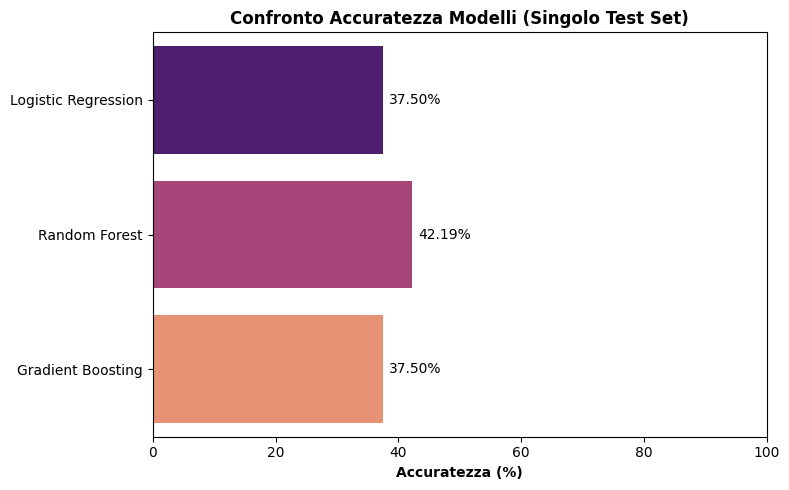

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

#SCALING E DEFINIZIONE DEI MODELLI

# Logistic Regression ha bisogno di dati normalizzati
scaler = StandardScaler()
X_train_smote_scaled = scaler.fit_transform(X_train_smote)
X_test_scaled = scaler.transform(X_test)

modelli = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

# ADDESTRAMENTO E CONFRONTO
risultati_accuracy = {}

for nome, modello in modelli.items():
    modello.fit(X_train_smote_scaled, y_train_smote)
    y_pred = modello.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred)
    risultati_accuracy[nome] = acc * 100

    print(f"✅ {nome}: {acc*100:.2f}%")

# PLOT DI CONFRONTO
df_risultati = pd.DataFrame(list(risultati_accuracy.items()), columns=['Modello', 'Accuratezza'])

plt.figure(figsize=(8, 5))
sns.barplot(x='Accuratezza', y='Modello', data=df_risultati, palette='magma')
plt.title('Confronto Accuratezza Modelli (Singolo Test Set)', fontweight='bold')
plt.xlabel('Accuratezza (%)', fontweight='bold')
plt.ylabel('')
plt.xlim(0, 100)
for index, value in enumerate(df_risultati['Accuratezza']):
    plt.text(value + 1, index, f'{value:.2f}%', va='center')
plt.tight_layout()
plt.show()

###cross-validation globale sui 3 modelli

In [ ]:
#CROSS-VALIDATION GLOBALE SUI MODELLI BASE

from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# le Pipeline sono fondamentali perché lo SMOTE e lo Scaler
# devono essere calcolati ogni volta solo sui dati di Train
modelli_pipeline = {
    "Logistic Regression Base": ImbPipeline([
        ('scaler', StandardScaler()),
        ('smote', SMOTE(random_state=42)),
        ('modello', LogisticRegression(max_iter=1000, random_state=42))
    ]),
    "Random Forest Base": ImbPipeline([
        ('smote', SMOTE(random_state=42)),
        ('modello', RandomForestClassifier(random_state=42))
    ]),
    "Gradient Boosting Base": ImbPipeline([
        ('smote', SMOTE(random_state=42)),
        ('modello', GradientBoostingClassifier(random_state=42))
    ])
}

# Testiamo ogni modello sul dataset intero
print("\nRisultati 5-fold CV:")
for nome, pipeline in modelli_pipeline.items():
    punteggi = cross_val_score(pipeline, X_encoded, y, cv=cv, scoring='accuracy')
    media_acc = punteggi.mean() * 100
    acc_min = punteggi.min() * 100
    acc_max = punteggi.max() * 100

    print(f"{nome}: {media_acc:.2f}% (Oscilla tra {acc_min:.2f}% e {acc_max:.2f}%)")


Risultati 5-fold CV:
Logistic Regression Base: 33.21% (Oscilla tra 25.00% e 46.88%)
Random Forest Base: 37.30% (Oscilla tra 32.81% e 43.75%)
Gradient Boosting Base: 32.29% (Oscilla tra 29.69% e 37.50%)


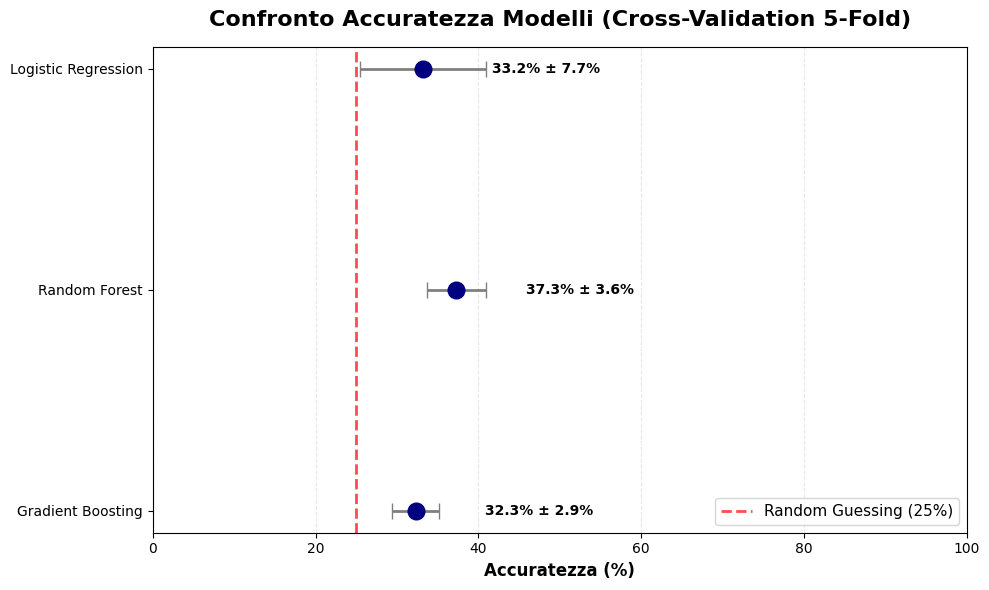

In [ ]:
#confronto grafico

fig, ax = plt.subplots(figsize=(10, 6))

modelli_nomi = ['Logistic Regression', 'Random Forest', 'Gradient Boosting']
medie = [33.2, 37.3, 32.3]
std_dev = [7.7, 3.6, 2.9]
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']

modelli_nomi_invertiti = modelli_nomi[::-1]
medie_invertite = medie[::-1]
std_dev_invertiti = std_dev[::-1]
colors_invertiti = colors[::-1]

ax.errorbar(medie_invertite, modelli_nomi_invertiti,
            xerr=std_dev_invertiti, fmt='o',
            markersize=12, color='navy',
            ecolor='gray', capsize=6, elinewidth=2)

# Linea verticale per il random guessing
ax.axvline(x=25, color='red', linestyle='--', linewidth=2,
           label='Random Guessing (25%)', alpha=0.7)

for i, (media, std) in enumerate(zip(medie_invertite, std_dev_invertiti)):
    ax.text(media + 8.5, i, f'{media:.1f}% ± {std:.1f}%',
            va='center', fontsize=10, fontweight='bold')

ax.set_xlim(0, 100)
ax.set_xlabel('Accuratezza (%)', fontsize=12, fontweight='bold')
ax.set_title('Confronto Accuratezza Modelli (Cross-Validation 5-Fold)',
             fontsize=16, fontweight='bold', pad=15)
ax.legend(loc='lower right', fontsize=11)
ax.grid(axis='x', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

#Gradient Boosting

##Gradient Boosting su singolo split

 Accuratezza del Modello: 37.50%

                         precision    recall  f1-score   support

       Trap/Nuova Scena       0.28      0.31      0.29        16
            Rap Storico       0.31      0.28      0.29        18
              Indie/Pop       0.59      0.54      0.57        24
Alternative/Elettronica       0.12      0.17      0.14         6

               accuracy                           0.38        64
              macro avg       0.33      0.32      0.32        64
           weighted avg       0.39      0.38      0.38        64



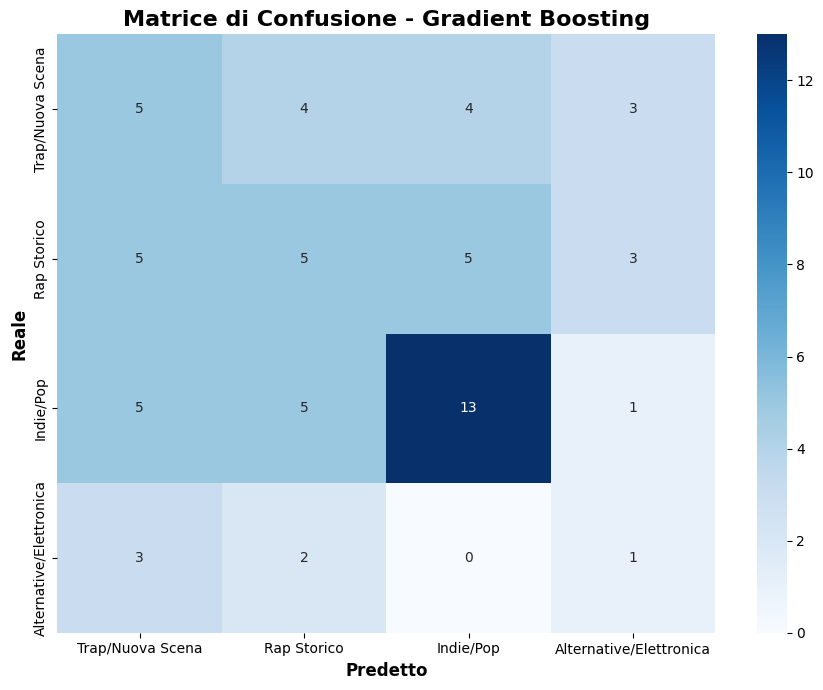

In [ ]:
# VALUTAZIONE di gradient boosting su singolo split
acc = accuracy_score(y_test, y_pred)
print(f" Accuratezza del Modello: {acc*100:.2f}%\n")

nomi_clusters = ['Trap/Nuova Scena','Rap Storico', 'Indie/Pop','Alternative/Elettronica']

print(classification_report(y_test, y_pred, target_names=nomi_clusters))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=nomi_clusters, yticklabels=nomi_clusters)
plt.title('Matrice di Confusione - Gradient Boosting', fontsize=16, fontweight='bold')
plt.xlabel('Predetto', fontsize=12, fontweight='bold')
plt.ylabel('Reale', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

####ESPERIMENTO: Accorpamento in 'Altro' delle variabili meno importanti

/tmp/ipykernel_3107/4085997798.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importanza', y='Feature', data=feat_imp_base_df, palette='viridis')


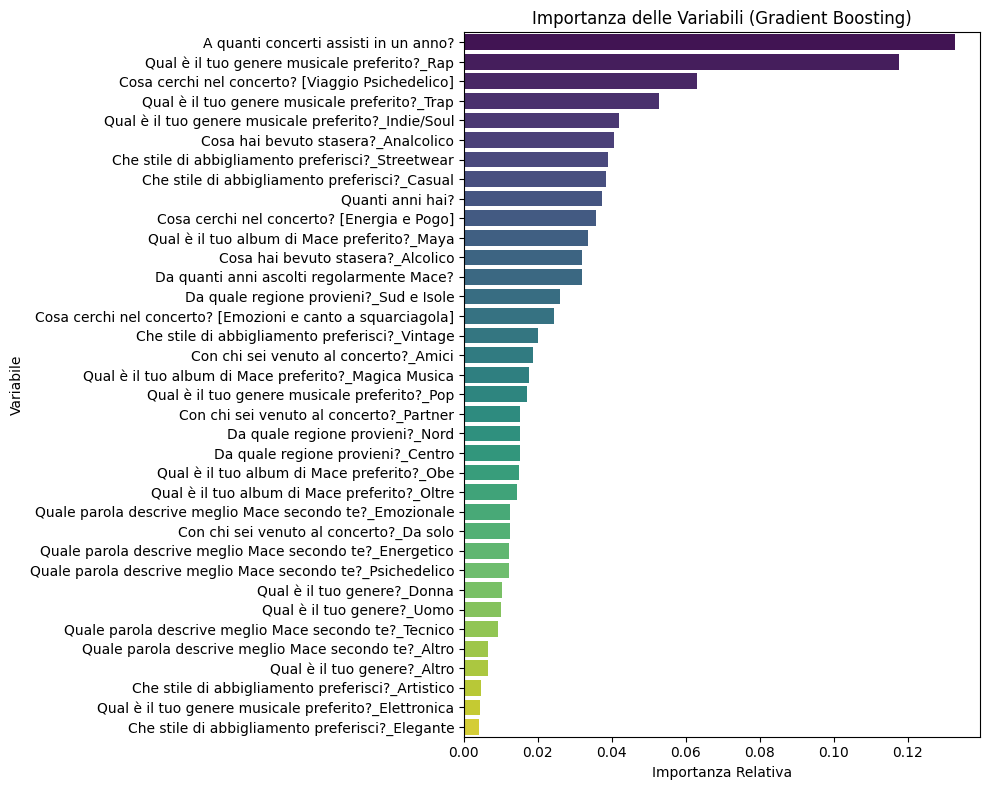


 Raggruppamenti effettuati:
   🔸 'Qual è il tuo genere?': ['Donna', 'Uomo', 'Altro'] -> 'Altro'
   🔸 'Che stile di abbigliamento preferisci?': ['Artistico', 'Elegante'] -> 'Altro'
   🔸 'Qual è il tuo genere musicale preferito?': ['Elettronica'] -> 'Altro'
   🔸 'Qual è il tuo album di Mace preferito?': ['Oltre'] -> 'Altro'
   🔸 'Con chi sei venuto al concerto?': ['Da solo'] -> 'Altro'
   🔸 'Quale parola descrive meglio Mace secondo te?': ['Emozionale', 'Energetico', 'Psichedelico', 'Tecnico', 'Altro'] -> 'Altro'

 RISULTATO SUL MODELLO BASE (COMPATTATO):
Accuratezza Iniziale (tutte le info, 36 colonne): 37.50%
Accuratezza Nuovo Modello ('Altro', 29 colonne): 37.50%


In [ ]:
# ESPERIMENTO : ACCORPAMENTO INTELLIGENTE SUL MODELLO BASE (37.50%)

# estrazione Feature Importance
gb_base_originale = GradientBoostingClassifier(random_state=42)
gb_base_originale.fit(X_train_smote, y_train_smote)
importances_base = gb_base_originale.feature_importances_

# DataFrame delle importanze per il modello base
feat_imp_base_df = pd.DataFrame({
    'Feature': X_train_smote.columns,
    'Importanza': importances_base
}).sort_values(by='Importanza', ascending=False)

plt.figure(figsize=(10, 8))
sns.barplot(x='Importanza', y='Feature', data=feat_imp_base_df, palette='viridis')
plt.title('Importanza delle Variabili (Gradient Boosting)')
plt.xlabel('Importanza Relativa')
plt.ylabel('Variabile')
plt.tight_layout()
plt.show()

# Troviamo le categorie deboli (< 1.5%)
soglia = 0.015   #prova 0.01
feature_deboli_base = feat_imp_base_df[feat_imp_base_df['Importanza'] <= soglia]['Feature'].tolist()

df_base_smart = df.copy()
X_temp_base = df_base_smart.drop(target_col, axis=1)
colonne_testuali_base = X_temp_base.select_dtypes(include=['object']).columns.tolist()

valori_da_raggruppare_base = {col: [] for col in colonne_testuali_base}

# nomi originali delle risposte
for feature in feature_deboli_base:
    for col in colonne_testuali_base:
        if feature.startswith(col + "_"):
            valore_debole = feature.replace(col + "_", "")
            valori_da_raggruppare_base[col].append(valore_debole)
            break

# raggruppamento in Altro
print("\n Raggruppamenti effettuati:")
for col, valori in valori_da_raggruppare_base.items():
    if valori:
        print(f"   🔸 '{col}': {valori} -> 'Altro'")
        df_base_smart[col] = df_base_smart[col].replace(valori, 'Altro')

# 5. Nuovo Preprocessing (Senza Scaling)
X_base_smart = df_base_smart.drop(target_col, axis=1)
X_encoded_base_smart = pd.get_dummies(X_base_smart, columns=colonne_testuali_base, dtype=int)

X_train_bs, X_test_bs, y_train_bs, y_test_bs = train_test_split(X_encoded_base_smart, y, test_size=0.2, random_state=42)

smote_bs = SMOTE(random_state=42)
X_train_bs_smote, y_train_bs_smote = smote_bs.fit_resample(X_train_bs, y_train_bs)

# Addestramento del Modello Base sul dataset compattato
gb_base_finale = GradientBoostingClassifier(random_state=42)
gb_base_finale.fit(X_train_bs_smote, y_train_bs_smote)
y_pred_bs = gb_base_finale.predict(X_test_bs)

# Valutazione
acc_bs = accuracy_score(y_test_bs, y_pred_bs)

print("\n RISULTATO SUL MODELLO BASE (COMPATTATO):")
print(f"Accuratezza Iniziale (tutte le info, {X_train_smote.shape[1]} colonne): {acc*100:.2f}%")
print(f"Accuratezza Nuovo Modello ('Altro', {X_train_bs_smote.shape[1]} colonne): {acc_bs*100:.2f}%")

##Gradient Boosting con parametri ottimizzati

In [ ]:
#OTTIMIZZAZIONE GRADIENT BOOSTING
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.ensemble import GradientBoostingClassifier
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

#  Pipeline rigorosa: SMOTE -> Scaler -> Modello
gb_pipeline = ImbPipeline([
    ('smote', SMOTE(random_state=42)),
    ('scaler', StandardScaler()),
    ('modello', GradientBoostingClassifier(random_state=42))
])

# Parametri da testare
param_grid_gb = {
    'modello__n_estimators': [50, 100, 150],
    'modello__max_depth': [2, 3, 5],
    'modello__learning_rate': [0.01, 0.05, 0.1]
}

# Validazione incrociata a 5 fold su TUTTO IL DATASET
cv_rigorosa = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid_gb_pipeline = GridSearchCV(
    estimator=gb_pipeline,
    param_grid=param_grid_gb,
    cv=cv_rigorosa,
    n_jobs=-1,
    scoring='accuracy'
)

print("\n⏳ Avvio ottimizzazione Gradient Boosting in Cross-Validation globale...")
grid_gb_pipeline.fit(X_encoded, y)

# Risultati: Media CV
miglior_media_gb = grid_gb_pipeline.best_score_ * 100

print(f"\nParametri ottimali trovati per il Gradient Boosting:")
print(grid_gb_pipeline.best_params_)
print(f"Accuratezza Media Globale (su 5 Fold CV): {miglior_media_gb:.2f}%")


⏳ Avvio ottimizzazione Gradient Boosting in Cross-Validation globale...

Parametri ottimali trovati per il Gradient Boosting:
{'modello__learning_rate': 0.01, 'modello__max_depth': 2, 'modello__n_estimators': 50}
Accuratezza Media Globale (su 5 Fold CV): 38.26%


In [ ]:
# ADDESTRAMENTO GRADIENT BOOSTING DEFINITIVO (SU TRAIN/TEST SPLIT)
best_params_gb_clean = {k.replace('modello__', ''): v for k, v in grid_gb_pipeline.best_params_.items()}

# Creiamo il modello definitivo con i parametri estratti
gb_definitivo = GradientBoostingClassifier(random_state=42, **best_params_gb_clean)

# Lo addestriamo sul Train set
gb_definitivo.fit(X_train_smote_scaled, y_train_smote)

# Lo testiamo sul Test set (precedentemente scalato)
y_pred_gb_definitivo = gb_definitivo.predict(X_test_scaled)
acc_gb_definitivo = accuracy_score(y_test, y_pred_gb_definitivo)

print(f"Accuratezza GB Ottimizzato (su Singolo Test Set): {acc_gb_definitivo*100:.2f}%")

Accuratezza GB Ottimizzato (su Singolo Test Set): 42.19%


###ESPERIMENTI sul Gradient Boosting migliore

#### Feature reduction con accorpamento intelligente

/tmp/ipykernel_3107/2591277416.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importanza', y='Feature', data=feat_imp_df, palette='viridis')


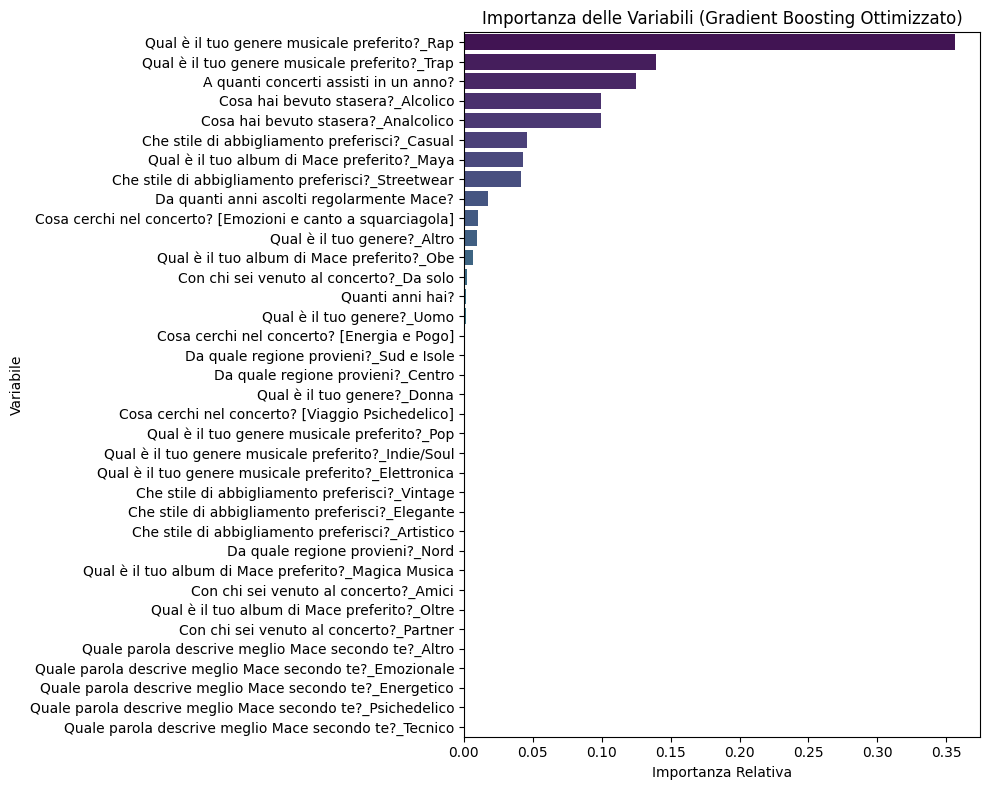


Top 5 variabili più importanti:
                                          Feature  Importanza
20   Qual è il tuo genere musicale preferito?_Rap    0.356593
21  Qual è il tuo genere musicale preferito?_Trap    0.139040
1           A quanti concerti assisti in un anno?    0.124983
29              Cosa hai bevuto stasera?_Alcolico    0.099793
30            Cosa hai bevuto stasera?_Analcolico    0.099442


In [ ]:
# FEATURE IMPORTANCE basata sul modello coi parametri migliori
importances = gb_definitivo.feature_importances_
features = X_train_smote.columns

feat_imp_df = pd.DataFrame({
    'Feature': features,
    'Importanza': importances
}).sort_values(by='Importanza', ascending=False)

# grafico
plt.figure(figsize=(10, 8))
sns.barplot(x='Importanza', y='Feature', data=feat_imp_df, palette='viridis')
plt.title('Importanza delle Variabili (Gradient Boosting Ottimizzato)')
plt.xlabel('Importanza Relativa')
plt.ylabel('Variabile')
plt.tight_layout()
plt.show()

print("\nTop 5 variabili più importanti:")
print(feat_imp_df.head(5))

In [ ]:
# ESPERIMENTO: ACCORPAMENTO INTELLIGENTE
from sklearn.base import clone

df_smart = df.copy()

soglia = 0.015   #ho provato 0.01, 0.015, 0.02
feature_deboli = feat_imp_df[feat_imp_df['Importanza'] <= soglia]['Feature'].tolist()

X_temporaneo = df_smart.drop(target_col, axis=1)
colonne_testuali = X_temporaneo.select_dtypes(include=['object']).columns.tolist()
valori_da_raggruppare = {col: [] for col in colonne_testuali}

for feature in feature_deboli:
    for col in colonne_testuali:
        if feature.startswith(col + "_"):
            valore_debole = feature.replace(col + "_", "")
            valori_da_raggruppare[col].append(valore_debole)
            break

# le risposte deboli diventano Altro
for col, valori in valori_da_raggruppare.items():
    if valori:
        print(f"🔸 Raggruppo in '{col}': {valori} -> 'Altro'")
        df_smart[col] = df_smart[col].replace(valori, 'Altro')

# Preprocessing sul nuovo dataset compattato
X_smart = df_smart.drop(target_col, axis=1)
X_encoded_smart = pd.get_dummies(X_smart, columns=colonne_testuali, dtype=int)

# Split, SMOTE e Scaling
X_train_sm, X_test_sm, y_train_sm, y_test_sm = train_test_split(X_encoded_smart, y, test_size=0.2, random_state=42)

smote_smart = SMOTE(random_state=42)
X_train_sm_smote, y_train_sm_smote = smote_smart.fit_resample(X_train_sm, y_train_sm)

scaler_smart = StandardScaler()
X_train_sm_scaled = scaler_smart.fit_transform(X_train_sm_smote)
X_test_sm_scaled = scaler_smart.transform(X_test_sm)

# addestramento miglior modello sui dati compattati
gb_smart = clone(gb_definitivo)
gb_smart.fit(X_train_sm_scaled, y_train_sm_smote)
y_pred_smart = gb_smart.predict(X_test_sm_scaled)

# Valutazione e Confronto Finale
acc_smart = accuracy_score(y_test_sm, y_pred_smart)

print(f"\n Acc. Modello Ottimizzato (Tutte le info, {X_train_smote.shape[1]} colonne): {acc_gb_definitivo*100:.2f}%")
print(f" Acc. Esperimento Accorpamento ('Altro', {X_train_sm_scaled.shape[1]} colonne): {acc_smart*100:.2f}%")


🔸 Raggruppo in 'Qual è il tuo genere?': ['Altro', 'Uomo', 'Donna'] -> 'Altro'
🔸 Raggruppo in 'Da quale regione provieni?': ['Sud e Isole', 'Centro', 'Nord'] -> 'Altro'
🔸 Raggruppo in 'Che stile di abbigliamento preferisci?': ['Vintage', 'Elegante', 'Artistico'] -> 'Altro'
🔸 Raggruppo in 'Qual è il tuo genere musicale preferito?': ['Pop', 'Indie/Soul', 'Elettronica'] -> 'Altro'
🔸 Raggruppo in 'Qual è il tuo album di Mace preferito?': ['Obe', 'Magica Musica', 'Oltre'] -> 'Altro'
🔸 Raggruppo in 'Con chi sei venuto al concerto?': ['Da solo', 'Amici', 'Partner'] -> 'Altro'
🔸 Raggruppo in 'Quale parola descrive meglio Mace secondo te?': ['Altro', 'Emozionale', 'Energetico', 'Psichedelico', 'Tecnico'] -> 'Altro'

 Acc. Modello Ottimizzato (Tutte le info, 36 colonne): 42.19%
 Acc. Esperimento Accorpamento ('Altro', 20 colonne): 40.62%


In [ ]:
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, accuracy_score
from imblearn.over_sampling import SMOTE

# 1. Creiamo la Pipeline corretta (SMOTE -> Scaler -> Modello)
# N.B. Usiamo X_train_sm e y_train_sm (quelli PRIMA della SMOTE manuale)
pipeline_gb = ImbPipeline([
    ('smote', SMOTE(random_state=42)),
    ('scaler', StandardScaler()),
    ('classifier', GradientBoostingClassifier(random_state=42))
])

# 2. Griglia dei parametri
# Nella pipeline, i parametri si indicano con il nome_dello_step + doppio underscore + parametro
param_grid_gb = {
    'classifier__n_estimators': [50, 100, 150],
    'classifier__learning_rate': [0.01, 0.05, 0.1],
    'classifier__max_depth': [2,3, 4, 5]
}

# 3. Configuriamo la GridSearchCV con la Pipeline
grid_search_gb = GridSearchCV(
    estimator=pipeline_gb,
    param_grid=param_grid_gb,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

# 4. Addestramento "Leakage-Free"
print("Inizio Grid Search GB (Leakage-Free). Potrebbe volerci qualche minuto...")
# Passiamo i dati NON processati dallo SMOTE. Ci pensa la pipeline.
grid_search_gb.fit(X_train_sm, y_train_sm)

print("\n" + "="*50)
print(f"✅ Migliori parametri Gradient Boosting:")
for param, value in grid_search_gb.best_params_.items():
    print(f"   - {param.replace('classifier__', '')}: {value}")
print("="*50 + "\n")

# 5. Valutazione Finale (Media 5-Fold Cross-Validation)
# Estraiamo direttamente l'accuratezza media calcolata sui 5 fold durante la Grid Search
acc_gb_cv_media = grid_search_gb.best_score_

print(f"📊 Accuratezza Media GB (5-Fold CV): {acc_gb_cv_media*100:.2f}%\n")

# Manteniamo la prediction sul test set solo per stampare il report dettagliato (Precision, Recall, F1)
y_pred_gb_ottimizzato = grid_search_gb.predict(X_test_sm)
print("Report Completo delle metriche sul Test Set:")
print(classification_report(y_test_sm, y_pred_gb_ottimizzato))

Inizio Grid Search GB (Leakage-Free). Potrebbe volerci qualche minuto...
Fitting 5 folds for each of 36 candidates, totalling 180 fits

✅ Migliori parametri Gradient Boosting:
   - learning_rate: 0.05
   - max_depth: 3
   - n_estimators: 50

📊 Accuratezza Media GB (5-Fold CV): 45.10%

Report Completo delle metriche sul Test Set:
              precision    recall  f1-score   support

           0       0.33      0.38      0.35        16
           1       0.38      0.44      0.41        18
           2       0.75      0.50      0.60        24
           3       0.22      0.33      0.27         6

    accuracy                           0.44        64
   macro avg       0.42      0.41      0.41        64
weighted avg       0.49      0.44      0.45        64



##valutazione modello


📊 METRICHE GLOBALI (GB OTTIMIZZATO):
   Accuracy (Media 5-Fold CV): 45.10%
   Precision (su Test Set):    49.26%
   Recall (su Test Set):       43.75%
   F1-Score (su Test Set):     45.36%

📑 REPORT DI CLASSIFICAZIONE PER CLASSE (Test Set):
                         precision    recall  f1-score   support

       Trap/Nuova Scena       0.33      0.38      0.35        16
            Rap Storico       0.38      0.44      0.41        18
              Indie/Pop       0.75      0.50      0.60        24
Alternative/Elettronica       0.22      0.33      0.27         6

               accuracy                           0.44        64
              macro avg       0.42      0.41      0.41        64
           weighted avg       0.49      0.44      0.45        64



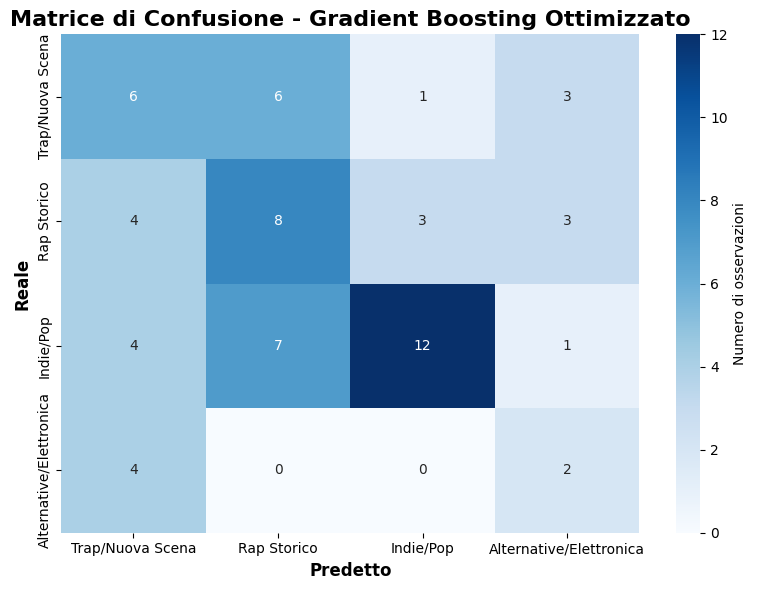


📈 METRICHE DETTAGLIATE PER CLASSE:
                 Classe  Precision  Recall  F1-Score  Support
       Trap/Nuova Scena     0.3333  0.3750    0.3529       16
            Rap Storico     0.3810  0.4444    0.4103       18
              Indie/Pop     0.7500  0.5000    0.6000       24
Alternative/Elettronica     0.2222  0.3333    0.2667        6
           Weighted Avg     0.4926  0.4375    0.4536       64


In [ ]:
# =========================================================
# VALUTAZIONE COMPLETA DEL MODELLO GB FINALE (OTTIMIZZATO)
# =========================================================
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. PREDIZIONI: Usiamo grid_search_gb e passiamo X_test_sm (NON scalato manualmente, ci pensa la pipeline)
y_pred_gb_final = grid_search_gb.predict(X_test_sm)
y_pred_proba_gb_final = grid_search_gb.predict_proba(X_test_sm)

# 2. METRICHE GLOBALI
# Usiamo l'accuratezza media dei 5 fold dalla Grid Search
accuracy_cv_gb = grid_search_gb.best_score_
precision_gb = precision_score(y_test_sm, y_pred_gb_final, average='weighted')
recall_gb = recall_score(y_test_sm, y_pred_gb_final, average='weighted')
f1_gb = f1_score(y_test_sm, y_pred_gb_final, average='weighted')

print(f"\n📊 METRICHE GLOBALI (GB OTTIMIZZATO):")
print(f"   Accuracy (Media 5-Fold CV): {accuracy_cv_gb*100:.2f}%")
print(f"   Precision (su Test Set):    {precision_gb*100:.2f}%")
print(f"   Recall (su Test Set):       {recall_gb*100:.2f}%")
print(f"   F1-Score (su Test Set):     {f1_gb*100:.2f}%")

# Report di classificazione per classe
print("\n📑 REPORT DI CLASSIFICAZIONE PER CLASSE (Test Set):")
print(classification_report(y_test_sm, y_pred_gb_final, target_names=nomi_clusters))

# Matrice di confusione
cm_gb = confusion_matrix(y_test_sm, y_pred_gb_final)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_gb, annot=True, fmt='d', cmap='Blues',
            xticklabels=nomi_clusters, yticklabels=nomi_clusters,
            cbar_kws={'label': 'Numero di osservazioni'})
plt.title('Matrice di Confusione - Gradient Boosting Ottimizzato', fontsize=16, fontweight='bold')
plt.xlabel('Predetto', fontsize=12, fontweight='bold')
plt.ylabel('Reale', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# Tabella metriche per classe
print("\n📈 METRICHE DETTAGLIATE PER CLASSE:")
class_metrics_gb = pd.DataFrame({
    'Classe': nomi_clusters,
    'Precision': precision_score(y_test_sm, y_pred_gb_final, average=None),
    'Recall': recall_score(y_test_sm, y_pred_gb_final, average=None),
    'F1-Score': f1_score(y_test_sm, y_pred_gb_final, average=None),
    'Support': [sum(y_test_sm == i) for i in range(len(nomi_clusters))]
})

# Media ponderata
media_gb = pd.DataFrame({
    'Classe': ['Weighted Avg'],
    'Precision': [precision_gb],
    'Recall': [recall_gb],
    'F1-Score': [f1_gb],
    'Support': [len(y_test_sm)]
})

# Unione tabelle
class_metrics_gb = pd.concat([class_metrics_gb, media_gb], ignore_index=True)
print(class_metrics_gb.round(4).to_string(index=False))

per i prossimi sondaggi possiamo ridurre le opzioni di risposta nei form inserendo direttamente la voce 'Altro' per le scelte minoritarie. Meno sforzo per l'utente, dati più puliti e modello meno complesso

N.B. con 0.2 test size viene 39.06% di accuracy. mettendo 0.25 diventa 37.50%


GENERAZIONE GRAFICI METRICHE E CONFIDENZA...

DATI METRICHE ORDINATI:
                 Classe  Precision  Recall  F1-Score  Support
Alternative/Elettronica     0.2222  0.3333    0.2667        6
       Trap/Nuova Scena     0.3333  0.3750    0.3529       16
            Rap Storico     0.3810  0.4444    0.4103       18
              Indie/Pop     0.7500  0.5000    0.6000       24


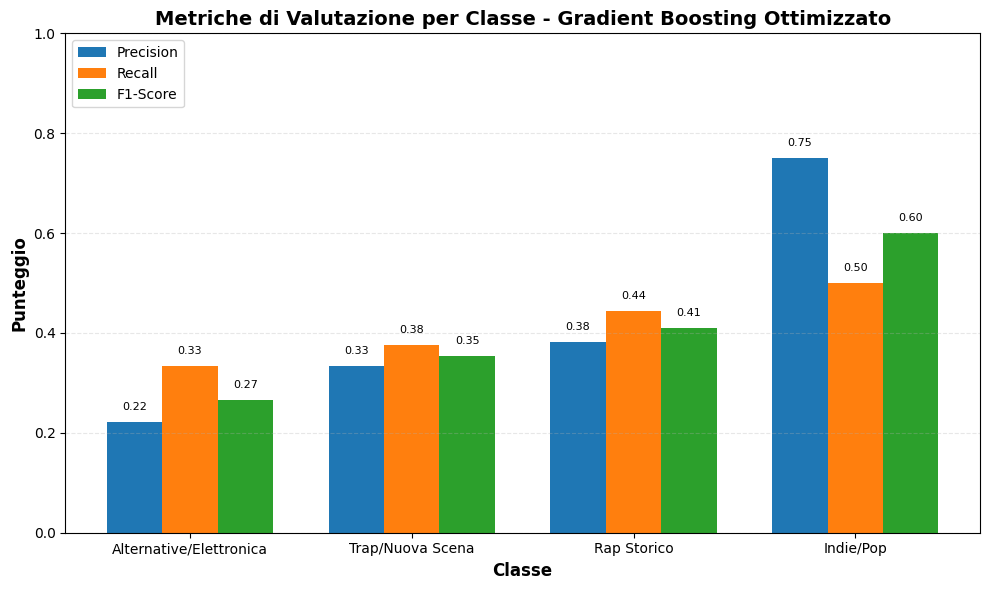

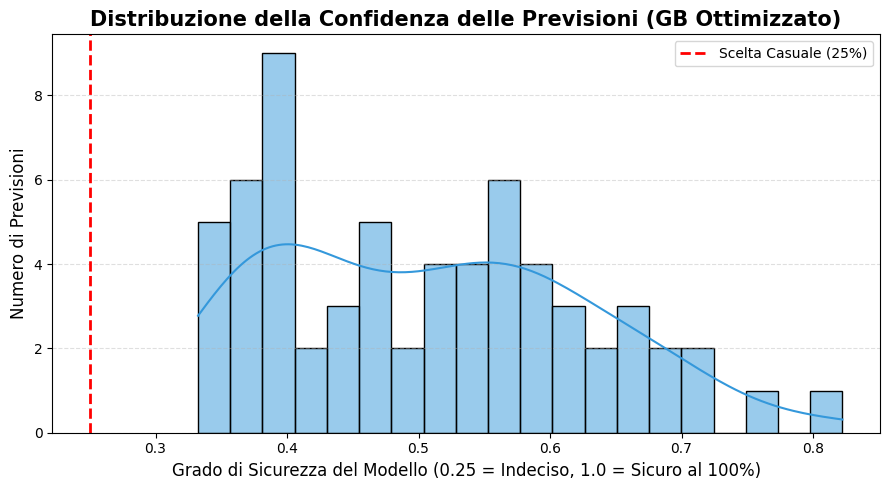

In [ ]:
# GRAFICI DELLE METRICHE DI VALUTAZIONE E CONFIDENZA (GB OTTIMIZZATO)
from sklearn.metrics import precision_score, recall_score, f1_score
import numpy as np

print("\nGENERAZIONE GRAFICI METRICHE E CONFIDENZA...")

# Calcolo metriche per classe
precision_per_class = precision_score(y_test_sm, y_pred_gb_final, average=None)
recall_per_class = recall_score(y_test_sm, y_pred_gb_final, average=None)
f1_per_class = f1_score(y_test_sm, y_pred_gb_final, average=None)
support_per_class = [sum(y_test_sm == i) for i in range(len(nomi_clusters))]

# Dataframe per i grafici
df_metrics = pd.DataFrame({
    'Classe': nomi_clusters,
    'Precision': precision_per_class,
    'Recall': recall_per_class,
    'F1-Score': f1_per_class,
    'Support': support_per_class
})

# Ordinamento per F1-score
df_metrics_sorted = df_metrics.sort_values('F1-Score', ascending=True)
print("\nDATI METRICHE ORDINATI:")
print(df_metrics_sorted.round(4).to_string(index=False))

# GRAFICO 1: Barplot metriche per classe
fig, ax = plt.subplots(figsize=(10, 6))
x = np.arange(len(df_metrics_sorted['Classe']))
width = 0.25

bars1 = ax.bar(x - width, df_metrics_sorted['Precision'], width, label='Precision', color='#1f77b4')
bars2 = ax.bar(x, df_metrics_sorted['Recall'], width, label='Recall', color='#ff7f0e')
bars3 = ax.bar(x + width, df_metrics_sorted['F1-Score'], width, label='F1-Score', color='#2ca02c')

ax.set_xlabel('Classe', fontsize=12, fontweight='bold')
ax.set_ylabel('Punteggio', fontsize=12, fontweight='bold')

ax.set_title('Metriche di Valutazione per Classe - Gradient Boosting Ottimizzato', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(df_metrics_sorted['Classe'])
ax.legend(loc='upper left')
ax.set_ylim(0, 1.0)
ax.grid(axis='y', linestyle='--', alpha=0.3)

for bars in [bars1, bars2, bars3]:
    for bar in bars:
        height = bar.get_height()
        if height > 0:
            ax.text(bar.get_x() + bar.get_width()/2., height + 0.02,
                    f'{height:.2f}', ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.show()

# GRAFICO 2: Distribuzione della confidenza (KDE)
prob_max = np.max(y_pred_proba_gb_final, axis=1)

plt.figure(figsize=(9, 5))
sns.histplot(prob_max, bins=20, kde=True, color='#3498db', edgecolor='black')

plt.axvline(x=0.25, color='red', linestyle='--', linewidth=2, label='Scelta Casuale (25%)')
# Titolo aggiornato
plt.title('Distribuzione della Confidenza delle Previsioni (GB Ottimizzato)', fontsize=15, fontweight='bold')
plt.xlabel('Grado di Sicurezza del Modello (0.25 = Indeciso, 1.0 = Sicuro al 100%)', fontsize=12)
plt.ylabel('Numero di Previsioni', fontsize=12)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

#Random Forest

##Random Forest con parametri ottimizzati

###calcolo accuracy media su 5 fold

In [ ]:
# ottimizzazione RANDOM FOREST (RICERCA SULLA MEDIA GLOBALE)
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# pipeline per evitare data leakage con lo smote
rf_pipeline = ImbPipeline([
    ('smote', SMOTE(random_state=42)),
    ('modello', RandomForestClassifier(random_state=42))
])

# parametri da testare
param_grid_rf_avanzata = {
    'modello__n_estimators': [100, 200, 300],
    'modello__max_depth': [5, 10, None],
    'modello__min_samples_leaf': [1, 2, 4],
    'modello__criterion': ['gini', 'entropy']
}

# validazione incrociata a 5 fold
cv_rigorosa = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid_rf_pipeline = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid_rf_avanzata,
    cv=cv_rigorosa,
    n_jobs=-1,
    scoring='accuracy'
)

grid_rf_pipeline.fit(X_encoded, y)

# Risultati
miglior_media_rf = grid_rf_pipeline.best_score_ * 100


print(f"\nParametri ottimali per il Random Forest:")
print(grid_rf_pipeline.best_params_)
print(f"Nuova Accuratezza Media (su 5 Fold): {miglior_media_rf:.2f}%")



Parametri ottimali per il Random Forest:
{'modello__criterion': 'entropy', 'modello__max_depth': 10, 'modello__min_samples_leaf': 4, 'modello__n_estimators': 200}
Nuova Accuratezza Media (su 5 Fold): 40.13%


resta uguale sia con 0.2 che 0.25 precedentemente

In [ ]:
# ADDESTRAMENTO RANDOM FOREST DEFINITIVO (SU TRAIN/TEST SPLIT)
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# modello con i parametri ottimali
rf_definitivo = RandomForestClassifier(
    criterion='entropy',
    max_depth=10,
    min_samples_leaf=4,
    n_estimators=200,
    random_state=42
)

rf_definitivo.fit(X_train_smote, y_train_smote)
y_pred_rf = rf_definitivo.predict(X_test)
acc_rf_definitivo = accuracy_score(y_test, y_pred_rf)

print(f"Accuratezza RF Ottimizzato (su Singolo Test Set): {acc_rf_definitivo*100:.2f}%")

Accuratezza RF Ottimizzato (su Singolo Test Set): 39.06%


con 0.25 test size era 42.50%

###accorpamento feature sul Random Forest

/tmp/ipykernel_3107/2054957774.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importanza', y='Feature', data=feat_imp_rf_df, palette='mako')


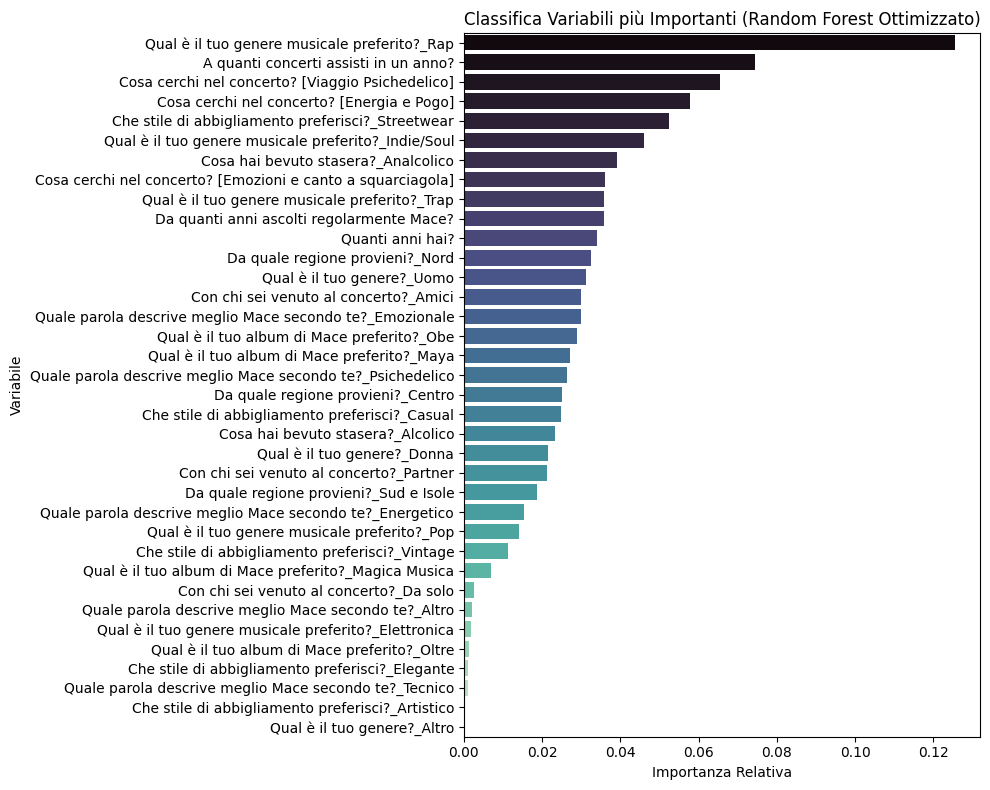


Top 5 variabili assolute che definiscono il fan di Mace:
                                              Feature  Importanza
20       Qual è il tuo genere musicale preferito?_Rap    0.125637
1               A quanti concerti assisti in un anno?    0.074417
4    Cosa cerchi nel concerto? [Viaggio Psichedelico]    0.065359
3          Cosa cerchi nel concerto? [Energia e Pogo]    0.057760
15  Che stile di abbigliamento preferisci?_Streetwear    0.052427


In [ ]:
# FEATURE IMPORTANCE DEL MODELLO DEFINITIVO (RANDOM FOREST)

rf_definitivo = grid_rf_pipeline.best_estimator_.named_steps['modello']
importances_rf = rf_definitivo.feature_importances_
features_rf = X_encoded.columns

# dataframe ordinato
feat_imp_rf_df = pd.DataFrame({
    'Feature': features_rf,
    'Importanza': importances_rf
}).sort_values(by='Importanza', ascending=False)

# grafico
plt.figure(figsize=(10, 8))
sns.barplot(x='Importanza', y='Feature', data=feat_imp_rf_df, palette='mako')
plt.title('Classifica Variabili più Importanti (Random Forest Ottimizzato)')
plt.xlabel('Importanza Relativa')
plt.ylabel('Variabile')
plt.tight_layout()
plt.show()

print("\nTop 5 variabili assolute che definiscono il fan di Mace:")
print(feat_imp_rf_df.head(5))

In [ ]:
# ESPERIMENTO FINALE: ACCORPAMENTO INTELLIGENTE SUL RANDOM FOREST

# Estrazione Feature Importance
importances_rf = rf_definitivo.feature_importances_
feat_imp_rf_df = pd.DataFrame({
    'Feature': X_train_smote.columns,
    'Importanza': importances_rf
}).sort_values(by='Importanza', ascending=False)

# Troviamo le risposte deboli (< 1.5%)
soglia_rf = 0.015
feature_deboli_rf = feat_imp_rf_df[feat_imp_rf_df['Importanza'] <= soglia_rf]['Feature'].tolist()

df_rf_smart = df.copy()
X_temp_rf = df_rf_smart.drop(target_col, axis=1)
colonne_testuali_rf = X_temp_rf.select_dtypes(include=['object']).columns.tolist()
valori_da_raggruppare_rf = {col: [] for col in colonne_testuali_rf}

for feature in feature_deboli_rf:
    for col in colonne_testuali_rf:
        if feature.startswith(col + "_"):
            valore_debole = feature.replace(col + "_", "")
            valori_da_raggruppare_rf[col].append(valore_debole)
            break

# sostituiamo con Altro
print("\nRaggruppamenti effettuati:")
for col, valori in valori_da_raggruppare_rf.items():
    if valori:
        print(f"   🔸 '{col}': {valori} -> 'Altro'")
        df_rf_smart[col] = df_rf_smart[col].replace(valori, 'Altro')

# Nuovo Preprocessing (Get Dummies + Split + SMOTE)
X_rf_smart = df_rf_smart.drop(target_col, axis=1)
X_encoded_rf_smart = pd.get_dummies(X_rf_smart, columns=colonne_testuali_rf, dtype=int)

X_train_rf, X_test_rf, y_train_rf, y_test_rf = train_test_split(X_encoded_rf_smart, y, test_size=0.2, random_state=42)

smote_rf = SMOTE(random_state=42)
X_train_rf_smote, y_train_rf_smote = smote_rf.fit_resample(X_train_rf, y_train_rf)

# Addestramento del MODELLO OTTIMIZZATO sui dati appena compattati
rf_smart_definitivo = RandomForestClassifier(
    criterion='entropy',
    max_depth=10,
    min_samples_leaf=4,
    n_estimators=200,
    random_state=42
)
rf_smart_definitivo.fit(X_train_rf_smote, y_train_rf_smote)
y_pred_rf_smart = rf_smart_definitivo.predict(X_test_rf)

# Valutazione e Confronto Finale
acc_rf_smart = accuracy_score(y_test_rf, y_pred_rf_smart)

print("\nRISULTATO FINALE RANDOM FOREST (COMPATTATO E OTTIMIZZATO):")
print(f" Acc. RF Ottimizzato (Tutte le info, {X_train_smote.shape[1]} colonne): {acc_rf_definitivo*100:.2f}%")
print(f" Acc. RF Ottimizzato (Risposte ridotte, {X_train_rf_smote.shape[1]} colonne): {acc_rf_smart*100:.2f}%")


Raggruppamenti effettuati:
   🔸 'Qual è il tuo genere?': ['Altro'] -> 'Altro'
   🔸 'Che stile di abbigliamento preferisci?': ['Vintage', 'Elegante', 'Artistico'] -> 'Altro'
   🔸 'Qual è il tuo genere musicale preferito?': ['Pop', 'Elettronica'] -> 'Altro'
   🔸 'Qual è il tuo album di Mace preferito?': ['Magica Musica', 'Oltre'] -> 'Altro'
   🔸 'Con chi sei venuto al concerto?': ['Da solo'] -> 'Altro'
   🔸 'Quale parola descrive meglio Mace secondo te?': ['Altro', 'Tecnico'] -> 'Altro'

RISULTATO FINALE RANDOM FOREST (COMPATTATO E OTTIMIZZATO):
 Acc. RF Ottimizzato (Tutte le info, 36 colonne): 39.06%
 Acc. RF Ottimizzato (Risposte ridotte, 31 colonne): 39.06%


In [ ]:
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score
from imblearn.over_sampling import SMOTE

# Pipeline
pipeline_rf = ImbPipeline([
    ('smote', SMOTE(random_state=42)),
    ('classifier', RandomForestClassifier(random_state=42))
])

# Griglia dei parametri
param_grid_rf = {
    'classifier__n_estimators': [100, 200, 300],
    'classifier__max_depth': [5, 10, None],
    'classifier__min_samples_leaf': [1, 2, 4],
    'classifier__criterion': ['gini', 'entropy']
}

# GridSearchCV
grid_search_rf = GridSearchCV(
    estimator=pipeline_rf,
    param_grid=param_grid_rf,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

# Addestramento "Leakage-Free"
print("Inizio Grid Search RF (Leakage-Free). Potrebbe volerci qualche minuto...")
# Usiamo X_train_rf (quello uscito direttamente dal train_test_split)
grid_search_rf.fit(X_train_rf, y_train_rf)

print("\n" + "="*50)
print(f"Migliori parametri Random Forest:")
for param, value in grid_search_rf.best_params_.items():
    print(f"   - {param.replace('classifier__', '')}: {value}")
print("="*50 + "\n")

# Valutazione Finale (Media 5-Fold Cross-Validation)
# Estraiamo direttamente l'accuratezza media calcolata sui 5 fold durante la Grid Search
acc_rf_cv_media = grid_search_rf.best_score_

print(f"Accuratezza Media RF (5-Fold CV): {acc_rf_cv_media*100:.2f}%\n")

# Manteniamo la prediction sul test set solo per stampare il report dettagliato (Precision, Recall, F1)
y_pred_rf_ottimizzato = grid_search_rf.predict(X_test_rf)
print("Report Completo delle metriche sul Test Set:")
print(classification_report(y_test_rf, y_pred_rf_ottimizzato))

Inizio Grid Search RF (Leakage-Free). Potrebbe volerci qualche minuto...
Fitting 5 folds for each of 54 candidates, totalling 270 fits

✅ Migliori parametri Random Forest:
   - criterion: entropy
   - max_depth: 10
   - min_samples_leaf: 1
   - n_estimators: 200

📊 Accuratezza Media RF (5-Fold CV): 44.71%

Report Completo delle metriche sul Test Set:
              precision    recall  f1-score   support

           0       0.30      0.38      0.33        16
           1       0.42      0.44      0.43        18
           2       0.61      0.46      0.52        24
           3       0.00      0.00      0.00         6

    accuracy                           0.39        64
   macro avg       0.33      0.32      0.32        64
weighted avg       0.42      0.39      0.40        64



##valutazione modello


METRICHE GLOBALI:
   Accuracy (Media 5-Fold CV): 44.71%
   Precision (su Test Set):    42.26%
   Recall (su Test Set):       39.06%
   F1-Score (su Test Set):     40.14%

REPORT DI CLASSIFICAZIONE PER CLASSE (Test Set):
                         precision    recall  f1-score   support

       Trap/Nuova Scena       0.30      0.38      0.33        16
            Rap Storico       0.42      0.44      0.43        18
              Indie/Pop       0.61      0.46      0.52        24
Alternative/Elettronica       0.00      0.00      0.00         6

               accuracy                           0.39        64
              macro avg       0.33      0.32      0.32        64
           weighted avg       0.42      0.39      0.40        64



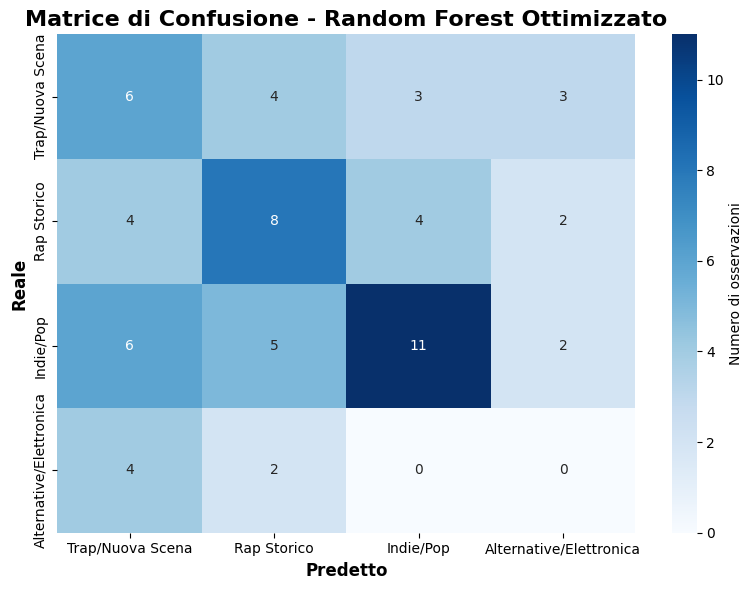


METRICHE PER CLASSE:
                 Classe  Precision  Recall  F1-Score  Support
       Trap/Nuova Scena     0.3000  0.3750    0.3333       16
            Rap Storico     0.4211  0.4444    0.4324       18
              Indie/Pop     0.6111  0.4583    0.5238       24
Alternative/Elettronica     0.0000  0.0000    0.0000        6
           Weighted Avg     0.4226  0.3906    0.4014       64


In [ ]:
# VALUTAZIONE COMPLETA DEL MODELLO FINALE (COMPATTATO E OTTIMIZZATO)
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# PREDIZIONI
y_pred_final = grid_search_rf.predict(X_test_rf)
y_pred_proba_final = grid_search_rf.predict_proba(X_test_rf)

#  METRICHE GLOBALI
accuracy_cv_final = grid_search_rf.best_score_
precision_final = precision_score(y_test_rf, y_pred_final, average='weighted')
recall_final = recall_score(y_test_rf, y_pred_final, average='weighted')
f1_final = f1_score(y_test_rf, y_pred_final, average='weighted')

print(f"\nMETRICHE GLOBALI:")
print(f"   Accuracy (Media 5-Fold CV): {accuracy_cv_final*100:.2f}%")
print(f"   Precision (su Test Set):    {precision_final*100:.2f}%")
print(f"   Recall (su Test Set):       {recall_final*100:.2f}%")
print(f"   F1-Score (su Test Set):     {f1_final*100:.2f}%")

# 3REPORT DI CLASSIFICAZIONE
print("\nREPORT DI CLASSIFICAZIONE PER CLASSE (Test Set):")
print(classification_report(y_test_rf, y_pred_final, target_names=nomi_clusters))

# MATRICE DI CONFUSIONE
cm_final = confusion_matrix(y_test_rf, y_pred_final)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_final, annot=True, fmt='d', cmap='Blues',
            xticklabels=nomi_clusters, yticklabels=nomi_clusters,
            cbar_kws={'label': 'Numero di osservazioni'})
plt.title('Matrice di Confusione - Random Forest Ottimizzato', fontsize=16, fontweight='bold')
plt.xlabel('Predetto', fontsize=12, fontweight='bold')
plt.ylabel('Reale', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# TABELLA METRICHE PER CLASSE
print("\nMETRICHE PER CLASSE:")
class_metrics_final = pd.DataFrame({
    'Classe': nomi_clusters,
    'Precision': precision_score(y_test_rf, y_pred_final, average=None),
    'Recall': recall_score(y_test_rf, y_pred_final, average=None),
    'F1-Score': f1_score(y_test_rf, y_pred_final, average=None),
    'Support': [sum(y_test_rf == i) for i in range(len(nomi_clusters))]
})

# media ponderata
media_final = pd.DataFrame({
    'Classe': ['Weighted Avg'],
    'Precision': [precision_final],
    'Recall': [recall_final],
    'F1-Score': [f1_final],
    'Support': [len(y_test_rf)]
})

class_metrics_final = pd.concat([class_metrics_final, media_final], ignore_index=True)
print(class_metrics_final.round(4).to_string(index=False))

per i prossimi sondaggi possiamo ridurre le opzioni di risposta nei form inserendo direttamente la voce 'Altro' per le scelte minoritarie. Meno sforzo per l'utente, dati più puliti e modello meno complesso

N.B. con 0.2 test size viene 39.06% di accuracy. mettendo 0.25 diventa 37.50%

                 Classe  Precision  Recall  F1-Score  Support
Alternative/Elettronica     0.0000  0.0000    0.0000        6
       Trap/Nuova Scena     0.3000  0.3750    0.3333       16
            Rap Storico     0.4211  0.4444    0.4324       18
              Indie/Pop     0.6111  0.4583    0.5238       24


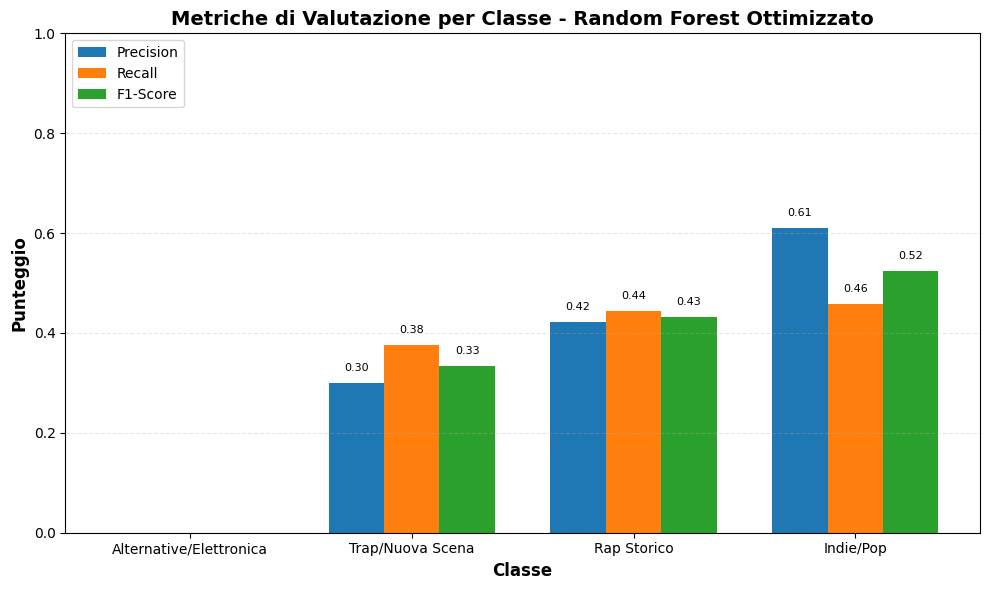

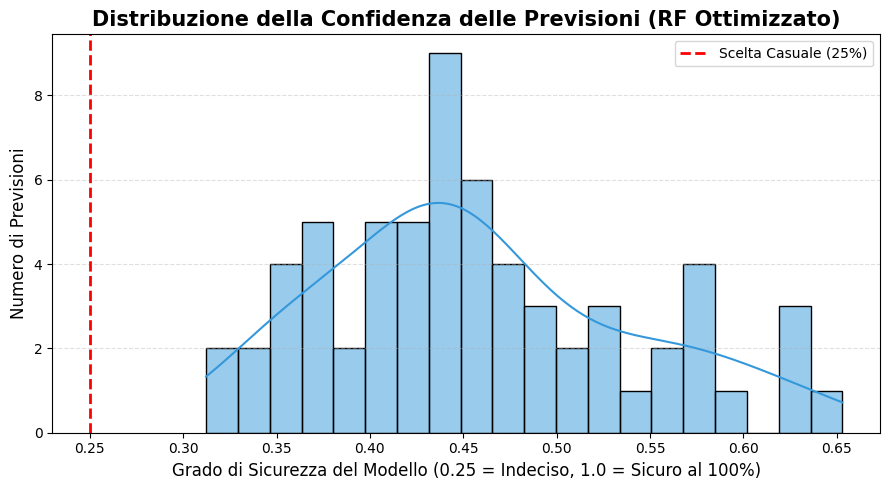

In [ ]:
# GRAFICI DELLE METRICHE DI VALUTAZIONE
import numpy as np

# Calcolo metriche per classe
precision_per_class = precision_score(y_test_rf, y_pred_final, average=None)
recall_per_class = recall_score(y_test_rf, y_pred_final, average=None)
f1_per_class = f1_score(y_test_rf, y_pred_final, average=None)
support_per_class = [sum(y_test_rf == i) for i in range(len(nomi_clusters))]

# Dataframe per i grafici
df_metrics = pd.DataFrame({
    'Classe': nomi_clusters,
    'Precision': precision_per_class,
    'Recall': recall_per_class,
    'F1-Score': f1_per_class,
    'Support': support_per_class
})

# Ordinamento per F1-score
df_metrics_sorted = df_metrics.sort_values('F1-Score', ascending=True)
print(df_metrics_sorted.round(4).to_string(index=False))

# BARPLOT METRICHE PER CLASSE
fig, ax = plt.subplots(figsize=(10, 6))
x = np.arange(len(df_metrics_sorted['Classe']))
width = 0.25

bars1 = ax.bar(x - width, df_metrics_sorted['Precision'], width, label='Precision', color='#1f77b4')
bars2 = ax.bar(x, df_metrics_sorted['Recall'], width, label='Recall', color='#ff7f0e')
bars3 = ax.bar(x + width, df_metrics_sorted['F1-Score'], width, label='F1-Score', color='#2ca02c')

ax.set_xlabel('Classe', fontsize=12, fontweight='bold')
ax.set_ylabel('Punteggio', fontsize=12, fontweight='bold')
# Titolo aggiornato
ax.set_title('Metriche di Valutazione per Classe - Random Forest Ottimizzato', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(df_metrics_sorted['Classe'])
ax.legend(loc='upper left')
ax.set_ylim(0, 1.0)
ax.grid(axis='y', linestyle='--', alpha=0.3)

for bars in [bars1, bars2, bars3]:
    for bar in bars:
        height = bar.get_height()
        if height > 0:
            ax.text(bar.get_x() + bar.get_width()/2., height + 0.02,
                    f'{height:.2f}', ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.show()

# GRAFICO DELLA DISTRIBUZIONE DELLA CONFIDENZA (KDE)
prob_max = np.max(y_pred_proba_final, axis=1)

plt.figure(figsize=(9, 5))
sns.histplot(prob_max, bins=20, kde=True, color='#3498db', edgecolor='black')

plt.axvline(x=0.25, color='red', linestyle='--', linewidth=2, label='Scelta Casuale (25%)')

plt.title('Distribuzione della Confidenza delle Previsioni (RF Ottimizzato)', fontsize=15, fontweight='bold')
plt.xlabel('Grado di Sicurezza del Modello (0.25 = Indeciso, 1.0 = Sicuro al 100%)', fontsize=12)
plt.ylabel('Numero di Previsioni', fontsize=12)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

La distribuzione della confidenza mostra che il modello assegna generalmente probabilità massime comprese tra 0.35 e 0.55, con poche predizioni prossime al livello di indecisione teorica (0.25 in un problema a quattro classi). Ciò suggerisce che il modello riesce spesso a identificare una classe preferita, pur mantenendo un grado di incertezza significativo. L'assenza di predizioni estremamente confidenti (>0.80) indica che il modello raramente considera una classe come nettamente dominante rispetto alle altre, un comportamento compatibile con la natura potenzialmente ambigua del fenomeno studiato.

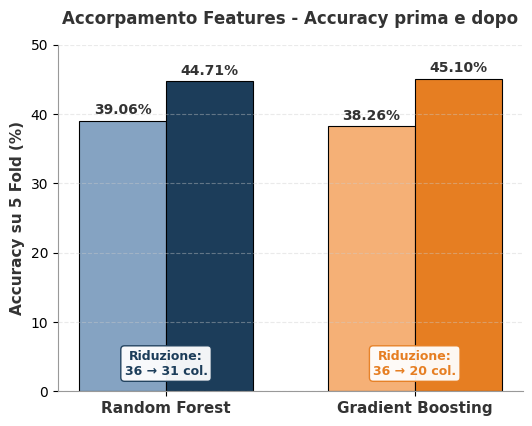

In [ ]:
import matplotlib.patches as mpatches

rf_prima = '#85A3C2' # Blu chiaro
rf_dopo = '#1C3D5A'  # Blu scuro

gb_prima = '#F5B076' # Arancione chiaro
gb_dopo = '#E67E22'  # Arancione scuro

# --- DATI ---
modelli = ['Random Forest', 'Gradient Boosting']
prima = [39.06, 38.26]
dopo = [44.71, 45.10]
colonne = ['Riduzione:\n36 → 31 col.', 'Riduzione:\n36 → 20 col.']

x = np.arange(len(modelli))
width = 0.35

# --- GRAFICO ---
fig, ax = plt.subplots(figsize=(6, 4.5))
fig.patch.set_facecolor('white')
ax.set_facecolor('white')

bar_rf_prima = ax.bar(x[0] - width/2, prima[0], width, color=rf_prima, edgecolor='black', linewidth=0.8)
bar_rf_dopo = ax.bar(x[0] + width/2, dopo[0], width, color=rf_dopo, edgecolor='black', linewidth=0.8)

bar_gb_prima = ax.bar(x[1] - width/2, prima[1], width, color=gb_prima, edgecolor='black', linewidth=0.8)
bar_gb_dopo = ax.bar(x[1] + width/2, dopo[1], width, color=gb_dopo, edgecolor='black', linewidth=0.8)

ax.set_ylabel('Accuracy su 5 Fold (%)', fontsize=11, fontweight='bold', color='#333')
ax.set_title('Accorpamento Features - Accuracy prima e dopo', fontsize=12, fontweight='bold', color='#333', pad=15)
ax.set_xticks(x)
ax.set_xticklabels(modelli, fontsize=11, fontweight='bold', color='#333')
ax.set_ylim(0, 50)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#999')
ax.spines['bottom'].set_color('#999')
ax.grid(axis='y', linestyle='--', alpha=0.4, color='#ccc')

# Funzione per aggiungere le percentuali sopra le barre
def add_labels(bars):
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height + 0.5,
                f'{height:.2f}%', ha='center', va='bottom', fontsize=10,
                fontweight='bold', color='#333')

add_labels(bar_rf_prima)
add_labels(bar_rf_dopo)
add_labels(bar_gb_prima)
add_labels(bar_gb_dopo)

props_rf = dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor=rf_dopo, alpha=0.95)
ax.text(x[0], 4, colonne[0], ha='center', va='center', fontsize=9, fontweight='bold', color=rf_dopo, bbox=props_rf)

props_gb = dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor=gb_dopo, alpha=0.95)
ax.text(x[1], 4, colonne[1], ha='center', va='center', fontsize=9, fontweight='bold', color=gb_dopo, bbox=props_gb)


patch_prima = mpatches.Patch(facecolor='#BDC3C7', edgecolor='black', label='Configurazione Base')
patch_dopo = mpatches.Patch(facecolor='#555555', edgecolor='black', label='Configurazione Accorpata')

plt.savefig('accorpamento_ottimizzato.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()